In [1]:
import pandas as pd

df = pd.read_excel('./data/Qiagtang_large.xlsx')

In [2]:
# Initialize new_df if it doesn't exist
new_df = pd.DataFrame()

# Selecting the best age using your existing logic
if 'Best Age' not in new_df.columns:
    if 'Published 206Pb/238U age (Ma)' in df.columns and 'Published 206Pb/207Pb age (Ma)' in df.columns:
        mask = df['Published 206Pb/238U age (Ma)'] < 1200
        new_df['Best Age'] = df.loc[mask, 'Published 206Pb/238U age (Ma)']
        new_df.loc[~mask, 'Best Age'] = df.loc[~mask, 'Published 206Pb/207Pb age (Ma)']
    elif 'Published 206Pb/238U age (Ma)' in df.columns:
        new_df['Best Age'] = df['Published 206Pb/238U age (Ma)']
    elif 'Published 206Pb/207Pb age (Ma)' in df.columns:
        new_df['Best Age'] = df['Published 206Pb/207Pb age (Ma)']

# Converting Latitude and Longitude to numeric and rounding
new_df['Latitude'] = pd.to_numeric(df['Latitude'], errors='coerce').dropna().apply(lambda x: round(x, 2))
new_df['Longitude'] = pd.to_numeric(df['Longitude'], errors='coerce').dropna().apply(lambda x: round(x, 2))

# Adding additional columns
additional_columns = [
    'Published_Sample_ID', 'Country/State', 'Region', 'Continent',
    'Major Geographic-Geologic Description', 'Minor Geologic-Geographic Unit',
    'Locality', 'Depos. Age (Epoch)', 'Mineral',
    'Class-1 Rock Type', 'Class-2 Rock Type', 'Class-3 Rock Type',
    'Th（ppm）', 'Pb（ppm）', 'U/Th', 'Th/U', 'Est. Depos. Age (Ma)'
]

for col in additional_columns:
    if col in df.columns:
        new_df[col] = df[col]

# Display the first few rows of the processed DataFrame
new_df

,Best Age,Latitude,Longitude,Published_Sample_ID,Region,Continent,Locality,Mineral,Class-1 Rock Type,Class-2 Rock Type,Class-3 Rock Type,Th（ppm）,Pb（ppm）,U/Th,Th/U,Est. Depos. Age (Ma)
0,54.0,32.92,88.75,06SDL24,Tibet,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,56.0,32.92,88.75,06SDL24,Tibet,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,57.3,32.92,88.75,06SDL24,Tibet,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,61.5,32.92,88.75,06SDL24,Tibet,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,65.0,32.92,88.75,06SDL24,Tibet,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
11826,2364.0,32.06,85.09,2013-TF08,Eastern Asia,Asia,south of Lake Zhaxicuo,zircon,detrital,siliciclastic,sandstone,NaN,NaN,NaN,NaN,130.0
11827,396.0,32.06,85.09,2013-TF08,Eastern Asia,Asia,south of Lake Zhaxicuo,zircon,detrital,siliciclastic,sandstone,NaN,NaN,NaN,NaN,130.0
11828,887.0,32.06,85.09,2013-TF08,Eastern Asia,Asia,south of Lake Zhaxicuo,zircon,detrital,siliciclastic,sandstone,NaN,NaN,NaN,NaN,130.0
11829,750.0,32.06,85.09,2013-TF08,Eastern Asia,Asia,south of Lake Zhaxicuo,zircon,detrital,siliciclastic,sandstone,NaN,NaN,NaN,NaN,130.0


In [3]:
grouped_ages = new_df.groupby('Published_Sample_ID').agg({
    'Best Age': list,
    'Est. Depos. Age (Ma)': 'first',  # Assuming a single value for each group
    'Latitude': 'first',  # Assuming a single latitude value for each group
    'Longitude': 'first'  # Assuming a single longitude value for each group
}).reset_index()

# Display the first few rows of the grouped DataFrame
grouped_ages

,Published_Sample_ID,Best Age,Est. Depos. Age (Ma),Latitude,Longitude
0,05AQ07,"[848.38, 2521.81, 841.62, 943.35, 551.28, 581....",NaN,33.27,85.18
1,05AQ10,"[1930.26, 1197.56, 1641.49, 917.89, 2323.01, 3...",NaN,33.32,85.19
2,05GT42,"[579.07, 1007.33, 793.23, 828.27, 2508.52, 259...",NaN,33.29,85.19
3,05GT56,"[1368.79, 766.86, 764.86, 542.98, 808.72, 794....",NaN,33.25,85.36
4,06AQ187,"[526.1978734, 529.2587826, 529.6548323, 530.22...",NaN,33.42,85.98
...,...,...,...,...,...
105,SS3,"[161.0, 172.0, 197.0, 200.0, 227.0, 231.0, 234...",19.0,34.95,92.95
106,T3,"[981.0, 974.0, 1435.0, 627.0, 2456.0, 994.0, 8...",465.0,33.28,85.25
107,T5,"[488.0, 597.0, 727.0, 1023.0, 698.0, 1462.0, 1...",465.0,33.28,85.25
108,TP10,"[1849.0, 328.0, 196.0, 906.0, 404.0, 944.0, 37...",35.0,33.91,92.61


In [4]:
import numpy as np
import pandas as pd

# 将非数值字符转换为NaN（如果需要）
grouped_ages['Est. Depos. Age (Ma)'] = pd.to_numeric(grouped_ages['Est. Depos. Age (Ma)'],
                                                     errors='coerce')

# 找出'Est. Depos. Age (Ma)'列中存在NaN值的行索引
nan_rows = grouped_ages['Est. Depos. Age (Ma)'].isna()

# 对于存在NaN值的行，找到同一行'Best Age'列中的最小数值
min_best_ages = grouped_ages.loc[nan_rows, 'Best Age'].apply(np.min)

# 用找到的最小'Best Age'值替换'Est. Depos. Age (Ma)'列的NaN值
grouped_ages.loc[nan_rows, 'Est. Depos. Age (Ma)'] = min_best_ages

grouped_ages

,Published_Sample_ID,Best Age,Est. Depos. Age (Ma),Latitude,Longitude
0,05AQ07,"[848.38, 2521.81, 841.62, 943.35, 551.28, 581....",333.510000,33.27,85.18
1,05AQ10,"[1930.26, 1197.56, 1641.49, 917.89, 2323.01, 3...",521.620000,33.32,85.19
2,05GT42,"[579.07, 1007.33, 793.23, 828.27, 2508.52, 259...",523.790000,33.29,85.19
3,05GT56,"[1368.79, 766.86, 764.86, 542.98, 808.72, 794....",303.840000,33.25,85.36
4,06AQ187,"[526.1978734, 529.2587826, 529.6548323, 530.22...",526.197873,33.42,85.98
...,...,...,...,...,...
105,SS3,"[161.0, 172.0, 197.0, 200.0, 227.0, 231.0, 234...",19.000000,34.95,92.95
106,T3,"[981.0, 974.0, 1435.0, 627.0, 2456.0, 994.0, 8...",465.000000,33.28,85.25
107,T5,"[488.0, 597.0, 727.0, 1023.0, 698.0, 1462.0, 1...",465.000000,33.28,85.25
108,TP10,"[1849.0, 328.0, 196.0, 906.0, 404.0, 944.0, 37...",35.000000,33.91,92.61


In [5]:
# 定义年龄区间和地质时代的映射
# geological_period = {
#     (0, 2.56): 'Quaternary',
#     (2.56, 23.03): 'Neogene',
#     (23.03, 66.0): 'Paleogene',
#     (66.0, 145.0): 'Cretaceous',
#     (145.0, 201.4): 'Jurassic',
#     (201.4, 251.902): 'Triassic',
#     (251.092, 298.9): 'Permian',
#     (298.9, 358.9): 'Carboniferous',
#     (358.9, 419.2): 'Devonian',
#     (418.2, 443.8): 'Silurian',
#     (443.8, 485.4): 'Ordovician',
#     (485.4, 538.9): 'Cambrian',
#     (538.9, 2500): 'Proterozoic',
#     (2500, 4031): 'Archean',
#     (4031, 4567): 'Hadean'
# }
geological_period = {
    (0, 2.56): 'Quaternary',
    (2.56, 23.03): 'Neogene',
    (23.03, 66.0): 'Paleogene',
    (66.0, 100.5): 'Upper Cretaceous',
    (100.5, 145.0): 'Lower Cretaceous',
    (145.0, 161.5): 'Upper Jurassic',
    (161.5, 174.7): 'Middle Jurassic',
    (174.7, 201.4): 'Lower Jurassic',
    (201.4, 237): 'Upper Triassic',
    (237, 247.2): 'Middle Triassic',
    (247.2, 251.9): 'Lower Triassic',
    (251.092, 298.9): 'Permian',
    (298.9, 358.9): 'Carboniferous',
    (358.9, 419.2): 'Devonian',
    (418.2, 443.8): 'Silurian',
    (443.8, 485.4): 'Ordovician',
    (485.4, 538.9): 'Cambrian',
    (538.9, 2500): 'Proterozoic',
    (2500, 4031): 'Archean',
    (4031, 4567): 'Hadean'
}

In [6]:
def assign_geological_period(age):
    for period_age_range, period_name in geological_period.items():
        lower_bound, upper_bound = period_age_range
        if lower_bound <= age <= upper_bound:
            return period_name
    raise ValueError(f"Age {age} does not fall within any defined geological period.")

grouped_ages['Geological_Period'] = grouped_ages['Est. Depos. Age (Ma)'].apply(assign_geological_period)
grouped_ages

,Published_Sample_ID,Best Age,Est. Depos. Age (Ma),Latitude,Longitude,Geological_Period
0,05AQ07,"[848.38, 2521.81, 841.62, 943.35, 551.28, 581....",333.510000,33.27,85.18,Carboniferous
1,05AQ10,"[1930.26, 1197.56, 1641.49, 917.89, 2323.01, 3...",521.620000,33.32,85.19,Cambrian
2,05GT42,"[579.07, 1007.33, 793.23, 828.27, 2508.52, 259...",523.790000,33.29,85.19,Cambrian
3,05GT56,"[1368.79, 766.86, 764.86, 542.98, 808.72, 794....",303.840000,33.25,85.36,Carboniferous
4,06AQ187,"[526.1978734, 529.2587826, 529.6548323, 530.22...",526.197873,33.42,85.98,Cambrian
...,...,...,...,...,...,...
105,SS3,"[161.0, 172.0, 197.0, 200.0, 227.0, 231.0, 234...",19.000000,34.95,92.95,Neogene
106,T3,"[981.0, 974.0, 1435.0, 627.0, 2456.0, 994.0, 8...",465.000000,33.28,85.25,Ordovician
107,T5,"[488.0, 597.0, 727.0, 1023.0, 698.0, 1462.0, 1...",465.000000,33.28,85.25,Ordovician
108,TP10,"[1849.0, 328.0, 196.0, 906.0, 404.0, 944.0, 37...",35.000000,33.91,92.61,Paleogene


In [7]:
import ast  

def clean_and_eval(s):  
    # 检查 s 是否是字符串  
    if isinstance(s, str):  
        # 去除字符串两端的空格  
        s = s.strip()  
        # 尝试转换清洗后的字符串为列表  
        try:  
            return ast.literal_eval(s)  
        except (ValueError, SyntaxError):  
            # 如果转换失败，返回空列表或其他适当的默认值  
            return []  
    # 如果 s 已经是列表，则直接返回  
    elif isinstance(s, list):  
        return s  
    else:  
        # 如果 s 不是字符串也不是列表，返回 None 或其他默认值  
        return None 
  
# 应用这个函数到 'Best Age' 列的每个元素  
grouped_ages['Best Age'] = grouped_ages['Best Age'].apply(clean_and_eval)  
  
# 现在你可以继续你的合并逻辑  
merged_ages = {}  
for index, row in grouped_ages.iterrows():  
    geological_period = row['Geological_Period']  
    best_age_list = row['Best Age']  
    if best_age_list is not None:  # 确保不是 None 或其他默认值  
        if geological_period in merged_ages:  
            merged_ages[geological_period].extend(best_age_list)  
        else:  
            merged_ages[geological_period] = best_age_list  
  
# 将合并后的字典转换为新的 DataFrame  
merged_df = pd.DataFrame(list(merged_ages.items()), columns=['Geological_Period', 'Merged Best Age'])  
  
# 显示合并后的 DataFrame  
print(merged_df)

   Geological_Period                                    Merged Best Age
0      Carboniferous  [848.38, 2521.81, 841.62, 943.35, 551.28, 581....
1           Cambrian  [1930.26, 1197.56, 1641.49, 917.89, 2323.01, 3...
2        Proterozoic  [539.5584458, 543.1183296, 563.9759514, 565.20...
3     Upper Triassic  [224.7981187, 231.6193505, 235.3973512, 245.30...
4           Silurian  [1112.9, 644.9, 687.5, 973.1, 804.8, 944.2, 11...
5          Paleogene  [54.0, 56.0, 57.3, 61.5, 65.0, 65.0, 66.0, 70....
6    Middle Jurassic  [162.0, 212.0, 217.0, 228.0, 242.0, 245.0, 250...
7         Quaternary  [43.3, 38.0, 40.1, 211.2, 38.6, 2027.7, 46.0, ...
8     Lower Triassic  [1058.0, 408.0, 473.4, 1725.6, 3387.6, 369.8, ...
9    Middle Triassic  [326.4, 258.6, 271.6, 473.2, 257.7, 516.1, 754...
10           Permian  [554.0, 1865.0, 1483.0, 308.0, 1128.0, 777.0, ...
11    Lower Jurassic  [758.0, 398.0, 921.0, 610.0, 1017.0, 946.0, 95...
12    Upper Jurassic  [95.0, 117.0, 123.0, 156.0, 163.0, 164.0, 

In [8]:
def process_geological_ages(df):  
    geological_ages = {}  
    for index, row in df.iterrows():  
        geological_period = row['Geological_Period']  
        merged_best_age = row['Merged Best Age']  
        geological_ages[geological_period + '_age'] = merged_best_age  
    return geological_ages  
  
# 使用函数并获取结果  
ages_dict = process_geological_ages(merged_df)

Carboniferous_age = ages_dict.get('Carboniferous_age')
Cambrian_age = ages_dict.get('Cambrian_age')
Proterozoic_age = ages_dict.get('Proterozoic_age')
Lower_Triassic_age = ages_dict.get('Lower Triassic_age')
Middle_Triassic_age = ages_dict.get('Middle Triassic_age')
Upper_Triassic_age = ages_dict.get('Upper Triassic_age')
Silurian_age = ages_dict.get('Silurian_age')
Paleogene_age = ages_dict.get('Paleogene_age')
Lower_Jurassic_age = ages_dict.get('Lower Jurassic_age')
Middle_Jurassic_age = ages_dict.get('Middle Jurassic_age')
Lower_Jurassic_age = ages_dict.get('Lower Jurassic_age')
Quaternary_age = ages_dict.get('Quaternary_age')
Permian_age = ages_dict.get('Permian_age')
Lower_Cretaceous_age = ages_dict.get('Lower Cretaceous_age')
Upper_Cretaceous_age = ages_dict.get('Upper Cretaceous_age')
Devonian_age = ages_dict.get('Devonian_age')
Ordovician_age = ages_dict.get('Ordovician_age')
Neogene_age = ages_dict.get('Neogene_age')

In [9]:
def list2series(lst):
    # 将列表转换为pandas Series  
    age_series = pd.Series(lst)  
    # 计算频率  
    freq_age = age_series.value_counts()  
    # 将频率转换为DataFrame  
    freq_df = pd.DataFrame(freq_age).reset_index()  
    # 重命名列  
    freq_df.columns = ['age', 'frequency']  
    # 按年龄排序  
    freq_df = freq_df.sort_values(by='age')  
    
    return freq_df

In [10]:
Quaternary_freq = list2series(ages_dict['Quaternary_age'])
Neogene_freq = list2series(ages_dict['Neogene_age'])
Paleogene_freq = list2series(ages_dict['Paleogene_age'])
Upper_Cretaceous_freq = list2series(ages_dict['Upper Cretaceous_age'])
Lower_Cretaceous_freq = list2series(ages_dict['Lower Cretaceous_age'])
Upper_Jurassic_freq = list2series(ages_dict['Upper Jurassic_age'])
Middle_Jurassic_freq = list2series(ages_dict['Middle Jurassic_age'])
Lower_Jurassic_freq = list2series(ages_dict['Lower Jurassic_age'])
Upper_Triassic_freq = list2series(ages_dict['Upper Triassic_age'])
Middle_Triassic_freq = list2series(ages_dict['Middle Triassic_age'])
Lower_Triassic_freq = list2series(ages_dict['Lower Triassic_age'])
Permian_freq = list2series(ages_dict['Permian_age'])
Carboniferous_freq = list2series(ages_dict['Carboniferous_age'])
Devonian_freq = list2series(ages_dict['Devonian_age'])
Silurian_freq = list2series(ages_dict['Silurian_age'])
Ordovician_freq = list2series(ages_dict['Ordovician_age'])
Cambrian_freq = list2series(ages_dict['Cambrian_age'])
Proterozoic_freq = list2series(ages_dict['Proterozoic_age'])

In [11]:
from statsmodels.nonparametric.smoothers_lowess import lowess 

def smooth_LOWESS(freq_df):
    # 将age和frequency提取为numpy数组  
    age = freq_df['age'].values  
    frequency = freq_df['frequency'].values  
    
    # 使用lowess函数进行LOESS拟合  
    # frac参数决定了平滑程度，可以根据需要调整  
    smoothed_points = lowess(frequency, age, frac=0.03)  
    
    # 提取平滑后的y值和x值  
    smoothed_y = [point[1] for point in smoothed_points]  
    smoothed_x = [point[0] for point in smoothed_points]
    
    return smoothed_x, smoothed_y

In [12]:
import matplotlib.pyplot as plt

def geological_period_plot(freq_df,ylim,period):

    age = freq_df['age']
    frequency = freq_df['frequency']
    
    plt.figure(figsize=(10, 3))
    plt.bar(age, frequency, width=5, color='Steelblue', label='frequency')
    plt.plot(smooth_LOWESS(freq_df)[0], smooth_LOWESS(freq_df)[1], color='red', label='smoothed')
    plt.xlabel('Age (Ma)')
    plt.ylabel('Frequency')
    plt.xlim(0, 3000)
    plt.ylim(0, ylim)
    plt.text(2600,(ylim-1),period,fontsize=10)
    plt.show()

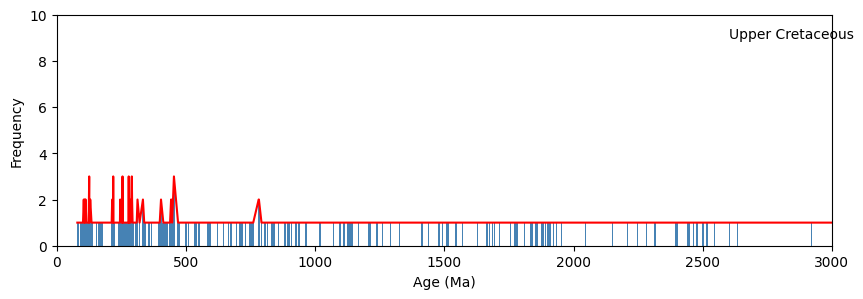

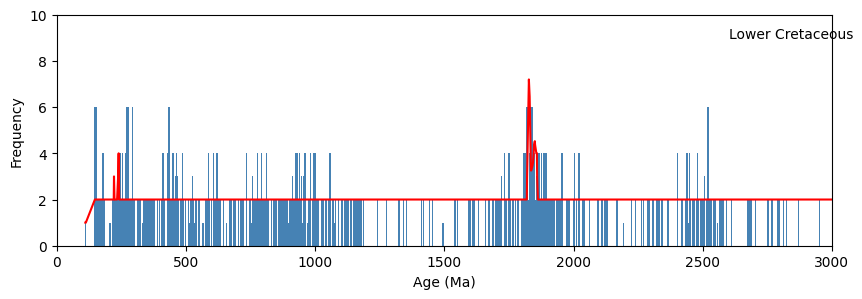

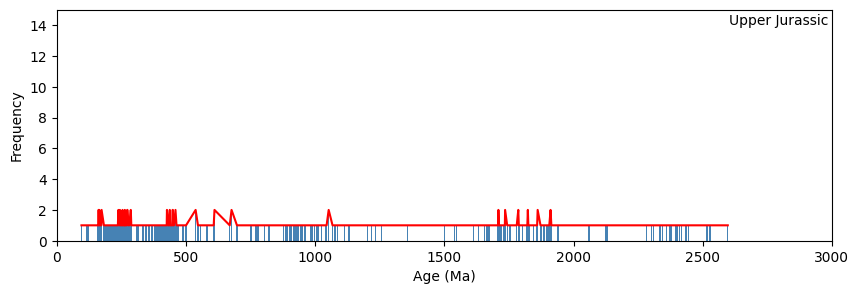

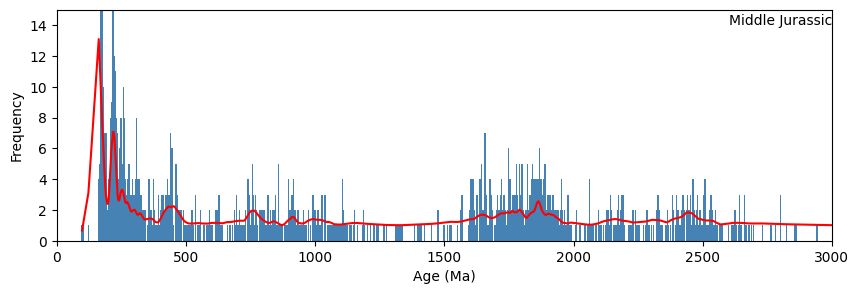

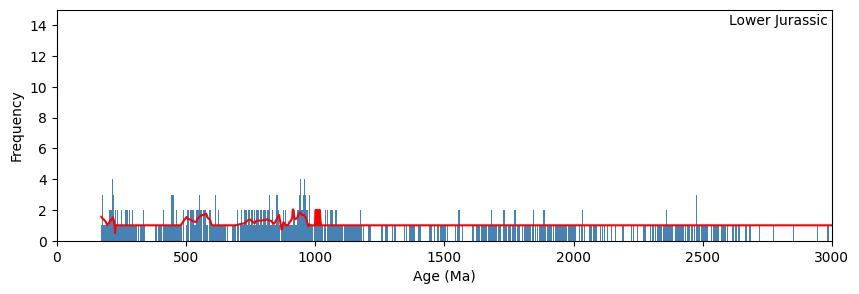

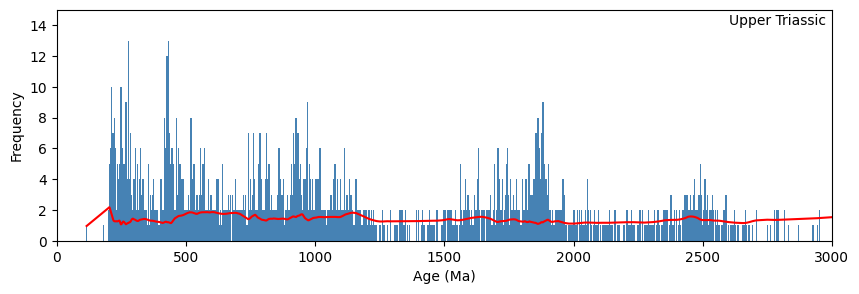

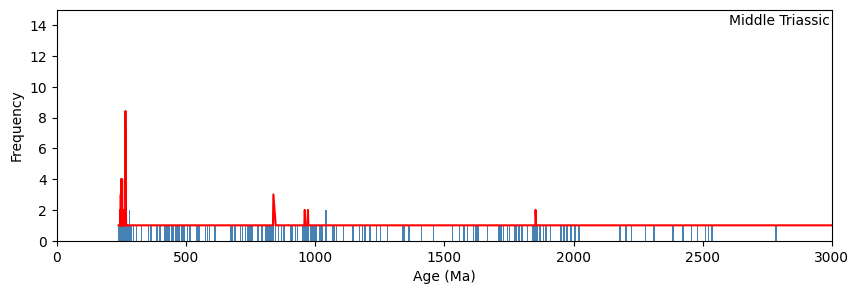

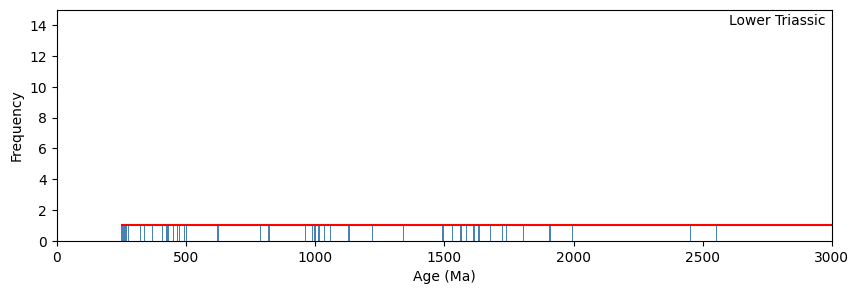

In [13]:

geological_period_plot(Upper_Cretaceous_freq,10,'Upper Cretaceous')
geological_period_plot(Lower_Cretaceous_freq,10,'Lower Cretaceous')
geological_period_plot(Upper_Jurassic_freq,15,'Upper Jurassic')
geological_period_plot(Middle_Jurassic_freq,15,'Middle Jurassic')
geological_period_plot(Lower_Jurassic_freq,15,'Lower Jurassic')
geological_period_plot(Upper_Triassic_freq,15,'Upper Triassic')
geological_period_plot(Middle_Triassic_freq,15,'Middle Triassic')
geological_period_plot(Lower_Triassic_freq,15,'Lower Triassic')


In [14]:
# geological_period_plot(Quaternary_freq,8,'Quaternary')
# geological_period_plot(Neogene_freq,4,'Neogene')
# geological_period_plot(Paleogene_freq,8,'Paleogene')
# geological_period_plot(Cretaceous_freq,10,'Cretaceous')
# geological_period_plot(Jurassic_freq,15,'Jurassic')
# geological_period_plot(Triassic_freq,15,'Triassic')
# geological_period_plot(Permian_freq,10,'Permian')
# geological_period_plot(Carboniferous_freq,6,'Carboniferous')
# geological_period_plot(Devonian_freq,4,'Devonian')
# geological_period_plot(Silurian_freq,4,'Silurian')
# geological_period_plot(Ordovician_freq,7,'Ordovician')
# geological_period_plot(Silurian_freq,7,'Silurian')
# geological_period_plot(Ordovician_freq,8,'Ordovician')
# geological_period_plot(Cambrian_freq,7,'Cambrian')
# geological_period_plot(Proterozoic_freq,7,'Proterozoic')

In [15]:
# Triassic_smooth_age, Triassic_smooth_freq = smooth_LOWESS(Triassic_freq)
# Jurassic_smooth_age, Jurassic_smooth_freq = smooth_LOWESS(Jurassic_freq)
# Cretaceous_smooth_age, Cretaceous_smooth_freq = smooth_LOWESS(Cretaceous_freq)

Lower_Triassic_smooth_age, Lower_Triassic_smooth_freq = smooth_LOWESS(Lower_Triassic_freq)
Middle_Triassic_smooth_age, Middle_Triassic_smooth_freq = smooth_LOWESS(Middle_Triassic_freq)
Upper_Triassic_smooth_age, Upper_Triassic_smooth_freq = smooth_LOWESS(Upper_Triassic_freq)
Lower_Jurassic_smooth_age, Lower_Jurassic_smooth_freq = smooth_LOWESS(Lower_Jurassic_freq)
Middle_Jurassic_smooth_age, Middle_Jurassic_smooth_freq = smooth_LOWESS(Middle_Jurassic_freq)
Upper_Jurassic_smooth_age, Upper_Jurassic_smooth_freq = smooth_LOWESS(Upper_Jurassic_freq)
Lower_Cretaceous_smooth_age, Lower_Cretaceous_smooth_freq = smooth_LOWESS(Lower_Cretaceous_freq)
Upper_Cretaceous_smooth_age, Upper_Cretaceous_smooth_freq = smooth_LOWESS(Upper_Cretaceous_freq)

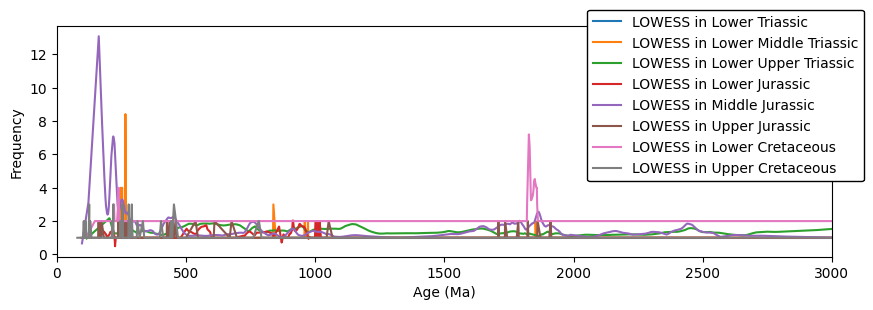

In [16]:
plt.figure(figsize=(10, 3))
plt.plot(Lower_Triassic_smooth_age, Lower_Triassic_smooth_freq, label='LOWESS in Lower Triassic')
plt.plot(Middle_Triassic_smooth_age, Middle_Triassic_smooth_freq, label='LOWESS in Lower Middle Triassic')
plt.plot(Upper_Triassic_smooth_age, Upper_Triassic_smooth_freq, label='LOWESS in Lower Upper Triassic')
plt.plot(Lower_Jurassic_smooth_age, Lower_Jurassic_smooth_freq, label='LOWESS in Lower Jurassic')
plt.plot(Middle_Jurassic_smooth_age, Middle_Jurassic_smooth_freq, label='LOWESS in Middle Jurassic')
plt.plot(Upper_Jurassic_smooth_age, Upper_Jurassic_smooth_freq, label='LOWESS in Upper Jurassic')
plt.plot(Lower_Cretaceous_smooth_age, Lower_Cretaceous_smooth_freq, label='LOWESS in Lower Cretaceous')
plt.plot(Upper_Cretaceous_smooth_age, Upper_Cretaceous_smooth_freq, label='LOWESS in Upper Cretaceous') 
plt.xlim(0, 3000)
plt.xlabel('Age (Ma)')
plt.ylabel('Frequency')
plt.legend(edgecolor='k',facecolor='white',loc='upper right',bbox_to_anchor=(1.05,1.10),framealpha=1)
plt.show()

In [17]:
import scipy.interpolate as interp 

def uniform_sampling(t_nonuniform, y_nonuniform, dt_uniform):
    
    # 设定均匀采样的时间间隔和总时间范围  
    dt_uniform = dt_uniform  # 均匀采样的时间间隔  
    t_start, t_end = t_nonuniform.min(), t_nonuniform.max()  # 均匀采样的时间范围  
    t_uniform = np.arange(t_start, t_end + dt_uniform, dt_uniform)  # 创建均匀的时间点  
    
    # 线性插值进行重采样  
    f_interp = interp.interp1d(t_nonuniform, y_nonuniform, kind='linear')  
    y_uniform = f_interp(t_uniform)  # 得到均匀采样的信号值

    return t_uniform, y_uniform

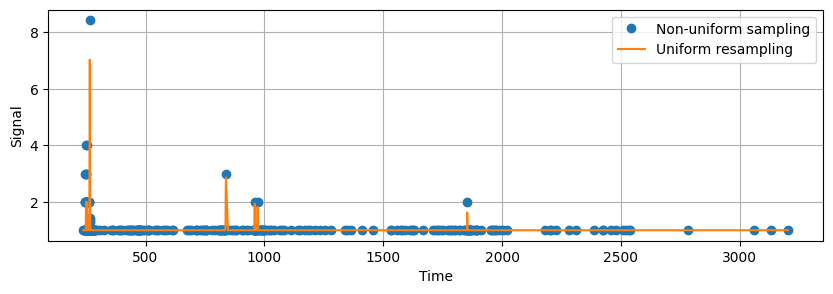

C:\Users\Administrator\AppData\Local\Temp\ipykernel_168568\1701019661.py:24: RuntimeWarning: divide by zero encountered in divide
  period_per_Ma = 1 / (fft_freq * 1e6 * 365.25 * 24 * 60 * 60)


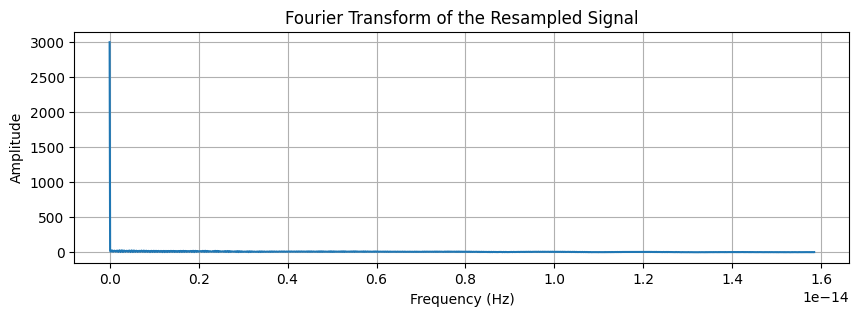

In [18]:
import numpy as np   
import matplotlib.pyplot as plt  

dt_uniform = 1
t_nonuniform = np.array(Middle_Triassic_smooth_age)
y_nonuniform = np.array(Middle_Triassic_smooth_freq)
t_uniform, y_uniform = uniform_sampling(t_nonuniform, y_nonuniform, dt_uniform)
  
# 绘制原始非均匀采样和重采样后的均匀采样数据  
plt.figure(figsize=(10, 3))  
plt.plot(t_nonuniform, y_nonuniform, 'o', label='Non-uniform sampling')  
plt.plot(t_uniform, y_uniform, '-', label='Uniform resampling')  
plt.xlabel('Time')  
plt.ylabel('Signal')  
plt.legend()  
plt.grid(True)  
plt.show()  
  
# fft
t_s = dt_uniform * 1e6 * 365.25 * 24 * 60 * 60    
fft_signal = np.fft.rfft(y_uniform)  
fft_freq = np.fft.rfftfreq(len(y_uniform), d=t_s)  

period_per_Ma = 1 / (fft_freq * 1e6 * 365.25 * 24 * 60 * 60)

# 绘制频谱图
plt.figure(figsize=(10, 3))  
plt.plot(fft_freq, np.abs(fft_signal))  
plt.xlabel('Frequency (Hz)')  
plt.ylabel('Amplitude')  
plt.title('Fourier Transform of the Resampled Signal')  
plt.grid(True)  
plt.show()

In [19]:
import numpy as np  
  
# selected_start 和 selected_end 选择区间的起始和结束索引  
selected_start, selected_end = 1700, 1900  # 您需要设定这些值  
  
# 提取所选区间的信号值  
selected_signal = y_uniform[selected_start:selected_end]  
  
# 计算所选区间的总幅度 
total_amplitude_selected = np.sum(np.abs(selected_signal))  
  
# 计算整个信号的总幅度  
total_amplitude_total = np.sum(np.abs(y_uniform))  
  
# 计算贡献度百分比  
contribution_percentage = (total_amplitude_selected / total_amplitude_total) * 100  
  
print(f"贡献度百分比为：{contribution_percentage:.2f}%")

贡献度百分比为：6.68%


In [21]:
import numpy as np  
from astropy.timeseries import LombScargle 
  
dt_uniform = 1
t_nonuniform = np.array(Middle_Triassic_smooth_age)
y_nonuniform = np.array(Middle_Triassic_smooth_freq)
t_uniform, y_uniform = uniform_sampling(t_nonuniform, y_nonuniform, dt_uniform)
  
# 计算Lomb-Scargle Periodogram  
frequency, power = LombScargle(t_uniform, y_uniform).autopower(maximum_frequency=np.max(np.diff(t_uniform)**(-1)))  
  
# 您感兴趣的时间区间  
selected_start, selected_end = 1700, 1900  
  
# 根据时间区间和采样率估计可能的频率范围  
# 采样间隔是均匀的，即 t[1] - t[0]  
sampling_interval = t_uniform[1] - t_uniform[0]  
time_interval = t_uniform[selected_end] - t_uniform[selected_start]  
min_period = time_interval  # 最短周期是时间区间的长度  
max_period = 2 * time_interval  # 最长周期取两倍的时间区间长度作为近似  
min_frequency = 1 / max_period  # 对应的最高频率  
max_frequency = 1 / min_period  # 对应的最低频率  
  
# 在Lomb-Scargle Periodogram中找到对应的功率值  
power_in_range = power[(frequency >= min_frequency) & (frequency <= max_frequency)]  
  
# 计算范围内功率的总和  
total_power_in_range = np.sum(power_in_range)  
  
# 计算Lomb-Scargle Periodogram的总功率  
total_power = np.sum(power)  
  
# 计算贡献率  
if total_power == 0:  
    contribution_rate = 0  
else:  
    contribution_rate = (total_power_in_range / total_power) * 100  
  
print(f"特定时间区间内可能的频率范围: [{min_frequency:.2f}, {max_frequency:.2f}] Hz")  
print(f"该频率范围内的总功率: {total_power_in_range}")  
print(f"Lomb-Scargle Periodogram的总功率: {total_power}")  
print(f"贡献率: {contribution_rate:.2f}%")

特定时间区间内可能的频率范围: [0.00, 0.01] Hz
该频率范围内的总功率: 0.09371892628233465
Lomb-Scargle Periodogram的总功率: 10.092798975527224
贡献率: 0.93%


特定时间区间内的总功率: (1.0000000000000004-5.1133919038772e-16j)
整个信号的总功率: (14.964767408397993-6.2727600891321345e-15j)
贡献率: 6.68-0.00j%


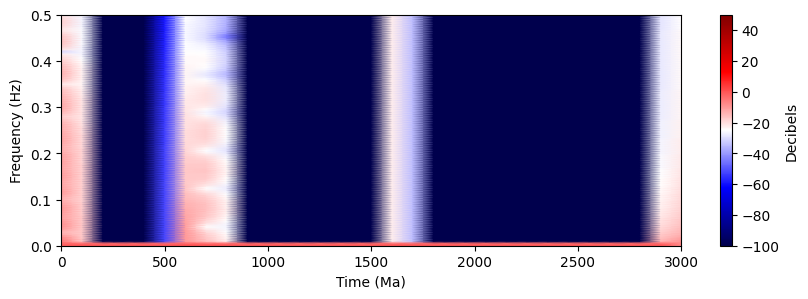

In [22]:
import numpy as np  
from scipy import signal  
import matplotlib.pyplot as plt  
  
dt_uniform = 1
t_nonuniform = np.array(Middle_Triassic_smooth_age)
y_nonuniform = np.array(Middle_Triassic_smooth_freq)
t_uniform, y_uniform = uniform_sampling(t_nonuniform, y_nonuniform, dt_uniform)
  
# 时间区间  
selected_start, selected_end = 1700, 1900  # 注意这里的索引值应根据信号数据
  
# 计算STFT  
fs = 1 / (t_uniform[1] - t_uniform[0])  # 采样频率  
nperseg = int(round(fs * 200.00))  # 每个段的长度
noverlap = int(nperseg // 2)  # 重叠的样本数  
freqs, times, Sxx = signal.stft(y_uniform, fs=fs, nperseg=nperseg, noverlap=noverlap, nfft=None, detrend=False, return_onesided=True, boundary='zeros', padded=True)  
  
# 提取所选时间区间的STFT结果  
selected_times = times[(times >= t_uniform[selected_start]) & (times <= t_uniform[selected_end])]  
selected_Sxx = Sxx[:, (times >= t_uniform[selected_start]) & (times <= t_uniform[selected_end])]  
  
# 计算所选时间区间内所有频率的总功率  
total_power_in_selected_time = np.sum(selected_Sxx, axis=1)  
  
# 计算整个信号的总功率  
total_power = np.sum(Sxx)  
  
# 计算贡献率  
if total_power == 0:  
    contribution_rate = 0  
else:  
    contribution_rate = (np.sum(total_power_in_selected_time) / total_power) * 100  
  
print(f"特定时间区间内的总功率: {np.sum(total_power_in_selected_time)}")  
print(f"整个信号的总功率: {total_power}")  
print(f"贡献率: {contribution_rate:.2f}%")  
  
# 绘制幅度谱（取对数前确保没有零值或非常小的值）  
amplitude_spectrum = np.abs(Sxx)  
db_spectrum = 10 * np.log10(amplitude_spectrum + 1e-10)  
  
# 设置图像的最小值和最大值  
vmin, vmax = -100, 50  # 根据你的数据调整这些值  
  
# 绘制 pcolormesh 并设置 vmin 和 vmax
plt.figure(figsize=(10, 3))
cmap = plt.get_cmap('seismic')  # 选择一个预定义的颜色映射       
plt.pcolormesh(times, freqs, db_spectrum, cmap=cmap, shading='gouraud', vmin=vmin, vmax=vmax)  
# 添加颜色条  
cbar = plt.colorbar(label='Decibels')  
# 显示图像  
plt.ylabel('Frequency (Hz)')  
plt.xlabel('Time (Ma)')  
plt.show()

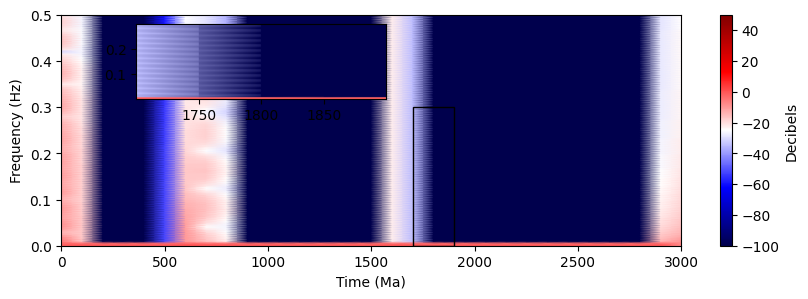

In [23]:
import numpy as np  
import matplotlib.pyplot as plt  
from matplotlib.patches import Rectangle  
  
# db_spectrum 的形状是 (n_times, n_freqs)  
n_times, n_freqs = db_spectrum.shape  
  
# 定义您想要放大的区域  
x_start, x_end = 1700, 1900  # 时间区间的开始和结束  
y_start, y_end = 0.0, 0.3  # 频率区间的开始和结束  

# 定义放大区域的频率范围和时间间隔
zoom_freq_range = (0, 0.3)  # Hz
zoom_time_interval = (selected_start, selected_end)  # Ma

# 索引频率和时间数组以获取放大区域
zoom_freq_indices = np.logical_and(freqs >= zoom_freq_range[0], freqs <= zoom_freq_range[1])
zoom_time_indices = np.logical_and(times >= zoom_time_interval[0], times <= zoom_time_interval[1])

# 提取放大区域的STFT结果
zoom_freqs = freqs[zoom_freq_indices]
zoom_times = times[zoom_time_indices]  # 用times而不是selected_times
zoom_db_spectrum = db_spectrum[zoom_freq_indices, :][:, zoom_time_indices]

# 绘制原始频谱图  
fig, ax1 = plt.subplots(figsize=(10, 3))  
cmap = plt.get_cmap('seismic')  
# 设置 vmin 和 vmax，这里假设您已经有了合适的值  
vmin, vmax = -100, 50  
pcm = ax1.pcolormesh(times, freqs, db_spectrum, cmap=cmap, shading='gouraud', vmin=vmin, vmax=vmax)  
ax1.set_ylabel('Frequency (Hz)')  
ax1.set_xlabel('Time (Ma)')  
# 在原始频谱图上绘制一个矩形，指示将要放大的区域  
rect = Rectangle((x_start, y_start), x_end - x_start, y_end - y_start, edgecolor='black', facecolor='none', linewidth=1)  
ax1.add_patch(rect)  

# 添加颜色条
fig.colorbar(pcm, ax=ax1, label='Decibels')

# 创建局部放大图的子图  
ax2 = fig.add_axes([0.2, 0.6, 0.25, 0.25])  
# 绘制局部放大图的频谱  
ax2.pcolormesh(zoom_times, zoom_freqs, zoom_db_spectrum, cmap=cmap, shading='gouraud', vmin=vmin, vmax=vmax) 
  
# 设置子图的坐标轴  
ax2.set_xticks([1750, 1800, 1850])  
ax2.set_yticks([0.1,0.2])  
 
plt.show()

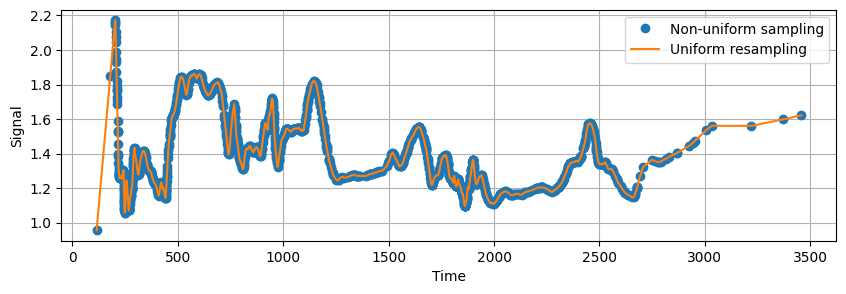

C:\Users\Administrator\AppData\Local\Temp\ipykernel_168568\572554389.py:24: RuntimeWarning: divide by zero encountered in divide
  period_per_Ma = 1 / (fft_freq * 1e6 * 365.25 * 24 * 60 * 60)


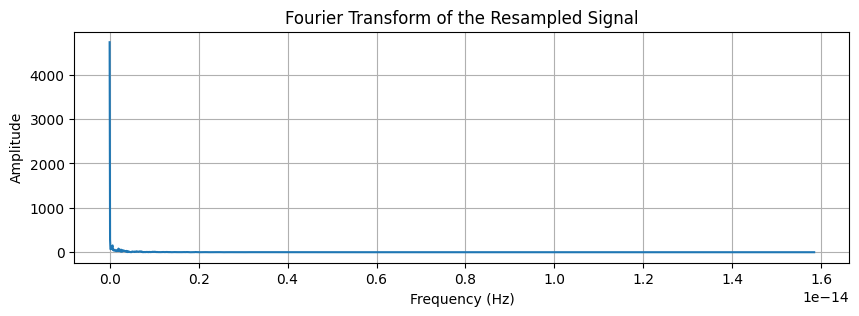

In [24]:
import numpy as np   
import matplotlib.pyplot as plt  

dt_uniform = 1
t_nonuniform = np.array(Upper_Triassic_smooth_age)
y_nonuniform = np.array(Upper_Triassic_smooth_freq)
t_uniform, y_uniform = uniform_sampling(t_nonuniform, y_nonuniform, dt_uniform)
  
# 绘制原始非均匀采样和重采样后的均匀采样数据  
plt.figure(figsize=(10, 3))  
plt.plot(t_nonuniform, y_nonuniform, 'o', label='Non-uniform sampling')  
plt.plot(t_uniform, y_uniform, '-', label='Uniform resampling')  
plt.xlabel('Time')  
plt.ylabel('Signal')  
plt.legend()  
plt.grid(True)  
plt.show()  
  
# fft
t_s = dt_uniform * 1e6 * 365.25 * 24 * 60 * 60    
fft_signal = np.fft.rfft(y_uniform)  
fft_freq = np.fft.rfftfreq(len(y_uniform), d=t_s)  

period_per_Ma = 1 / (fft_freq * 1e6 * 365.25 * 24 * 60 * 60)

# 绘制频谱图（如果需要的话）  
plt.figure(figsize=(10, 3))  
plt.plot(fft_freq, np.abs(fft_signal))  
plt.xlabel('Frequency (Hz)')  
plt.ylabel('Amplitude')  
plt.title('Fourier Transform of the Resampled Signal')  
plt.grid(True)  
plt.show()

In [25]:
import numpy as np  
from astropy.timeseries import LombScargle 
  
dt_uniform = 1
t_nonuniform = np.array(Upper_Triassic_smooth_age)
y_nonuniform = np.array(Upper_Triassic_smooth_freq)
t_uniform, y_uniform = uniform_sampling(t_nonuniform, y_nonuniform, dt_uniform)
  
# 计算Lomb-Scargle Periodogram  
frequency, power = LombScargle(t_uniform, y_uniform).autopower(maximum_frequency=np.max(np.diff(t_uniform)**(-1)))  
  
# 您感兴趣的时间区间  
selected_start, selected_end = 1700, 1900  
  
# 根据时间区间和采样率估计可能的频率范围  
# 采样间隔是均匀的，即 t[1] - t[0]  
sampling_interval = t_uniform[1] - t_uniform[0]  
time_interval = t_uniform[selected_end] - t_uniform[selected_start]  
min_period = time_interval  # 最短周期是时间区间的长度  
max_period = 2 * time_interval  # 最长周期取两倍的时间区间长度作为近似  
min_frequency = 1 / max_period  # 对应的最高频率  
max_frequency = 1 / min_period  # 对应的最低频率  
  
# 在Lomb-Scargle Periodogram中找到对应的功率值  
power_in_range = power[(frequency >= min_frequency) & (frequency <= max_frequency)]  
  
# 计算范围内功率的总和  
total_power_in_range = np.sum(power_in_range)  
  
# 计算Lomb-Scargle Periodogram的总功率  
total_power = np.sum(power)  
  
# 计算贡献率  
if total_power == 0:  
    contribution_rate = 0  
else:  
    contribution_rate = (total_power_in_range / total_power) * 100  
  
print(f"特定时间区间内可能的频率范围: [{min_frequency:.2f}, {max_frequency:.2f}] Hz")  
print(f"该频率范围内的总功率: {total_power_in_range}")  
print(f"Lomb-Scargle Periodogram的总功率: {total_power}")  
print(f"贡献率: {contribution_rate:.2f}%")

特定时间区间内可能的频率范围: [0.00, 0.01] Hz
该频率范围内的总功率: 0.41573957592140076
Lomb-Scargle Periodogram的总功率: 11.784125499126901
贡献率: 3.53%


特定时间区间内的总功率: (1.1603456084255017+0.0010348242721425738j)
整个信号的总功率: (23.66729351187074-9.631184738623233e-15j)
贡献率: 4.90+0.00j%


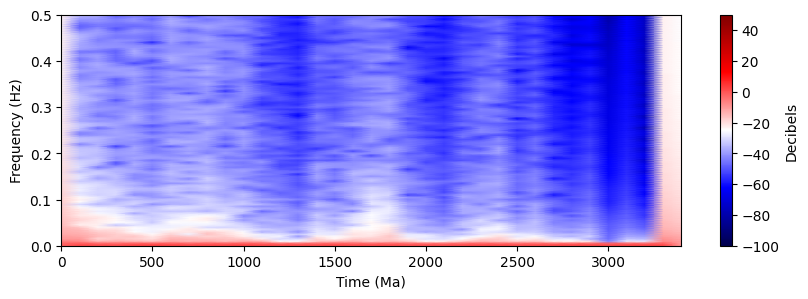

In [26]:
import numpy as np  
from scipy import signal  
import matplotlib.pyplot as plt  
  
dt_uniform = 1
t_nonuniform = np.array(Upper_Triassic_smooth_age)
y_nonuniform = np.array(Upper_Triassic_smooth_freq)
t_uniform, y_uniform = uniform_sampling(t_nonuniform, y_nonuniform, dt_uniform)
  
# 时间区间  
selected_start, selected_end = 1700, 1900  # 注意这里的索引值应根据信号数据
  
# 计算STFT  
fs = 1 / (t_uniform[1] - t_uniform[0])  # 采样频率  
nperseg = int(round(fs * 200.00))  # 每个段的长度
noverlap = int(nperseg // 2)  # 重叠的样本数  
freqs, times, Sxx = signal.stft(y_uniform, fs=fs, nperseg=nperseg, noverlap=noverlap, nfft=None, detrend=False, return_onesided=True, boundary='zeros', padded=True)  
  
# 提取所选时间区间的STFT结果  
selected_times = times[(times >= t_uniform[selected_start]) & (times <= t_uniform[selected_end])]  
selected_Sxx = Sxx[:, (times >= t_uniform[selected_start]) & (times <= t_uniform[selected_end])]  
  
# 计算所选时间区间内所有频率的总功率  
total_power_in_selected_time = np.sum(selected_Sxx, axis=1)  
  
# 计算整个信号的总功率  
total_power = np.sum(Sxx)  
  
# 计算贡献率  
if total_power == 0:  
    contribution_rate = 0  
else:  
    contribution_rate = (np.sum(total_power_in_selected_time) / total_power) * 100  
  
print(f"特定时间区间内的总功率: {np.sum(total_power_in_selected_time)}")  
print(f"整个信号的总功率: {total_power}")  
print(f"贡献率: {contribution_rate:.2f}%")  
  
# 绘制幅度谱（取对数前确保没有零值或非常小的值）  
amplitude_spectrum = np.abs(Sxx)  
db_spectrum = 10 * np.log10(amplitude_spectrum + 1e-10)  
  
# 设置图像的最小值和最大值  
vmin, vmax = -100, 50  # 根据你的数据调整这些值  
  
# 绘制 pcolormesh 并设置 vmin 和 vmax
plt.figure(figsize=(10, 3))
cmap = plt.get_cmap('seismic')  # 选择一个预定义的颜色映射       
plt.pcolormesh(times, freqs, db_spectrum, cmap=cmap, shading='gouraud', vmin=vmin, vmax=vmax)  
# 添加颜色条  
cbar = plt.colorbar(label='Decibels')  
# 显示图像  
plt.ylabel('Frequency (Hz)')  
plt.xlabel('Time (Ma)')  
plt.show()

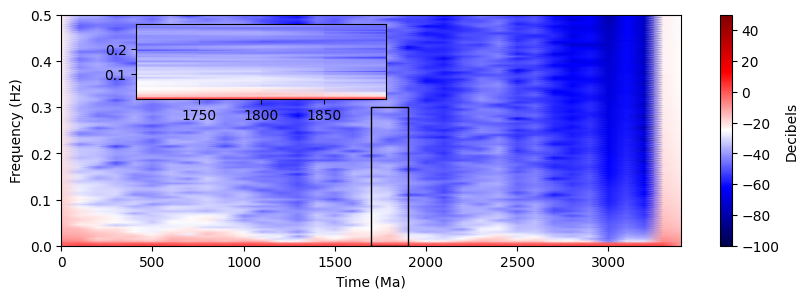

In [27]:
import numpy as np  
import matplotlib.pyplot as plt  
from matplotlib.patches import Rectangle  
  
# db_spectrum 的形状是 (n_times, n_freqs)  
n_times, n_freqs = db_spectrum.shape  
  
# 定义您想要放大的区域  
x_start, x_end = 1700, 1900  # 时间区间的开始和结束  
y_start, y_end = 0.0, 0.3  # 频率区间的开始和结束  

# 定义放大区域的频率范围和时间间隔
zoom_freq_range = (0, 0.3)  # Hz
zoom_time_interval = (selected_start, selected_end)  # Ma

# 索引频率和时间数组以获取放大区域
zoom_freq_indices = np.logical_and(freqs >= zoom_freq_range[0], freqs <= zoom_freq_range[1])
zoom_time_indices = np.logical_and(times >= zoom_time_interval[0], times <= zoom_time_interval[1])

# 提取放大区域的STFT结果
zoom_freqs = freqs[zoom_freq_indices]
zoom_times = times[zoom_time_indices]  # 用times而不是selected_times
zoom_db_spectrum = db_spectrum[zoom_freq_indices, :][:, zoom_time_indices]

# 绘制原始频谱图  
fig, ax1 = plt.subplots(figsize=(10, 3))  
cmap = plt.get_cmap('seismic')  
# 设置 vmin 和 vmax，这里假设您已经有了合适的值  
vmin, vmax = -100, 50  
pcm = ax1.pcolormesh(times, freqs, db_spectrum, cmap=cmap, shading='gouraud', vmin=vmin, vmax=vmax)  
ax1.set_ylabel('Frequency (Hz)')  
ax1.set_xlabel('Time (Ma)')  
# 在原始频谱图上绘制一个矩形，指示将要放大的区域  
rect = Rectangle((x_start, y_start), x_end - x_start, y_end - y_start, edgecolor='black', facecolor='none', linewidth=1)  
ax1.add_patch(rect)  

# 添加颜色条
fig.colorbar(pcm, ax=ax1, label='Decibels')

# 创建局部放大图的子图  
ax2 = fig.add_axes([0.2, 0.6, 0.25, 0.25])  
# 绘制局部放大图的频谱  
ax2.pcolormesh(zoom_times, zoom_freqs, zoom_db_spectrum, cmap=cmap, shading='gouraud', vmin=vmin, vmax=vmax) 
  
# 设置子图的坐标轴  
ax2.set_xticks([1750, 1800, 1850])  
ax2.set_yticks([0.1,0.2])  
 
plt.show()

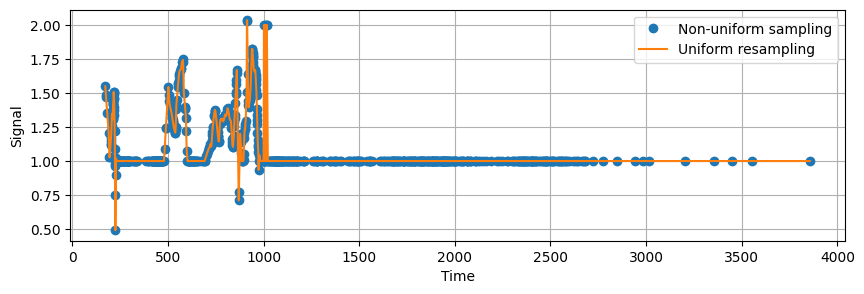

C:\Users\Administrator\AppData\Local\Temp\ipykernel_168568\1065504039.py:24: RuntimeWarning: divide by zero encountered in divide
  period_per_Ma = 1 / (fft_freq * 1e6 * 365.25 * 24 * 60 * 60)


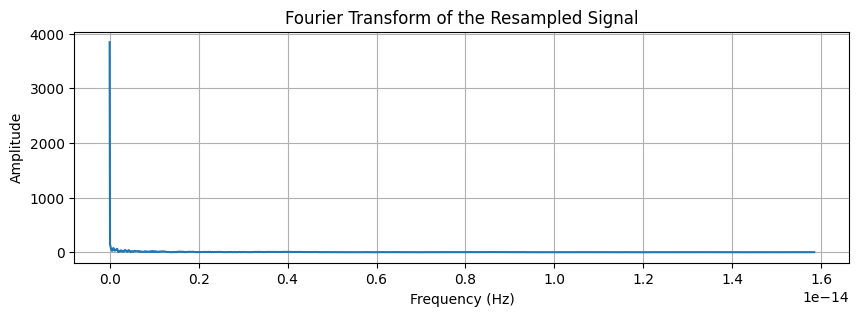

In [28]:
import numpy as np   
import matplotlib.pyplot as plt  

dt_uniform = 1
t_nonuniform = np.array(Lower_Jurassic_smooth_age)
y_nonuniform = np.array(Lower_Jurassic_smooth_freq)
t_uniform, y_uniform = uniform_sampling(t_nonuniform, y_nonuniform, dt_uniform)
  
# 绘制原始非均匀采样和重采样后的均匀采样数据  
plt.figure(figsize=(10, 3))  
plt.plot(t_nonuniform, y_nonuniform, 'o', label='Non-uniform sampling')  
plt.plot(t_uniform, y_uniform, '-', label='Uniform resampling')  
plt.xlabel('Time')  
plt.ylabel('Signal')  
plt.legend()  
plt.grid(True)  
plt.show()  
  
# fft
t_s = dt_uniform * 1e6 * 365.25 * 24 * 60 * 60    
fft_signal = np.fft.rfft(y_uniform)  
fft_freq = np.fft.rfftfreq(len(y_uniform), d=t_s)  

period_per_Ma = 1 / (fft_freq * 1e6 * 365.25 * 24 * 60 * 60)

# 绘制频谱图（如果需要的话）  
plt.figure(figsize=(10, 3))  
plt.plot(fft_freq, np.abs(fft_signal))  
plt.xlabel('Frequency (Hz)')  
plt.ylabel('Amplitude')  
plt.title('Fourier Transform of the Resampled Signal')  
plt.grid(True)  
plt.show()

In [29]:
import numpy as np  
  
# selected_start 和 selected_end 是所选区间的起始和结束索引  
selected_start, selected_end = 1700, 1900  # 您需要设定这些值  
  
# 提取所选区间的信号值  
selected_signal = y_uniform[selected_start:selected_end]  
  
# 计算所选区间的总能量或总幅度（这里以幅度为例）  
total_amplitude_selected = np.sum(np.abs(selected_signal))  
  
# 计算整个信号的总能量或总幅度  
total_amplitude_total = np.sum(np.abs(y_uniform))  
  
# 计算贡献度百分比  
contribution_percentage = (total_amplitude_selected / total_amplitude_total) * 100  
  
print(f"贡献度百分比为：{contribution_percentage:.2f}%")

贡献度百分比为：5.20%


In [30]:
import numpy as np  
from astropy.timeseries import LombScargle 
  
dt_uniform = 1
t_nonuniform = np.array(Lower_Jurassic_smooth_age)
y_nonuniform = np.array(Lower_Jurassic_smooth_freq)
t_uniform, y_uniform = uniform_sampling(t_nonuniform, y_nonuniform, dt_uniform)
  
# 计算Lomb-Scargle Periodogram  
frequency, power = LombScargle(t_uniform, y_uniform).autopower(maximum_frequency=np.max(np.diff(t_uniform)**(-1)))  
  
# 您感兴趣的时间区间  
selected_start, selected_end = 1700, 1900  
  
# 根据时间区间和采样率估计可能的频率范围  
# 假设采样间隔是均匀的，即 t[1] - t[0]  
sampling_interval = t_uniform[1] - t_uniform[0]  
time_interval = t_uniform[selected_end] - t_uniform[selected_start]  
min_period = time_interval  # 最短周期是时间区间的长度  
max_period = 2 * time_interval  # 最长周期取两倍的时间区间长度作为近似  
min_frequency = 1 / max_period  # 对应的最高频率  
max_frequency = 1 / min_period  # 对应的最低频率  
  
# 在Lomb-Scargle Periodogram中找到对应的功率值  
power_in_range = power[(frequency >= min_frequency) & (frequency <= max_frequency)]  
  
# 计算范围内功率的总和  
total_power_in_range = np.sum(power_in_range)  
  
# 计算Lomb-Scargle Periodogram的总功率  
total_power = np.sum(power)  
  
# 计算贡献率  
if total_power == 0:  
    contribution_rate = 0  
else:  
    contribution_rate = (total_power_in_range / total_power) * 100  
  
print(f"特定时间区间内可能的频率范围: [{min_frequency:.2f}, {max_frequency:.2f}] Hz")  
print(f"该频率范围内的总功率: {total_power_in_range}")  
print(f"Lomb-Scargle Periodogram的总功率: {total_power}")  
print(f"贡献率: {contribution_rate:.2f}%")

特定时间区间内可能的频率范围: [0.00, 0.01] Hz
该频率范围内的总功率: 0.8865028563240025
Lomb-Scargle Periodogram的总功率: 11.204677734818077
贡献率: 7.91%


特定时间区间内的总功率: (0.9999999999999988-3.494931975016598e-16j)
整个信号的总功率: (19.228278315208208-7.16093850883226e-15j)
贡献率: 5.20+0.00j%


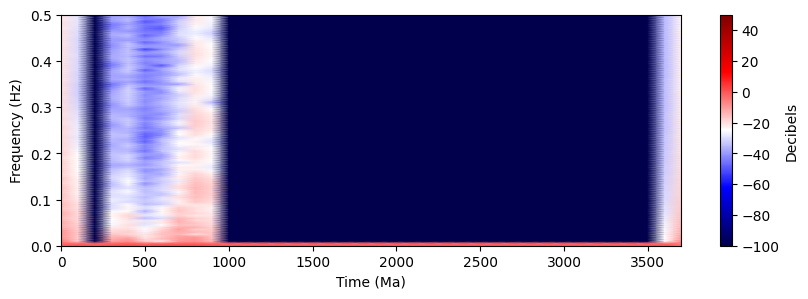

In [31]:
import numpy as np  
from scipy import signal  
import matplotlib.pyplot as plt  
  
dt_uniform = 1
t_nonuniform = np.array(Lower_Jurassic_smooth_age)
y_nonuniform = np.array(Lower_Jurassic_smooth_freq)
t_uniform, y_uniform = uniform_sampling(t_nonuniform, y_nonuniform, dt_uniform)
  
# 您感兴趣的时间区间  
selected_start, selected_end = 1700, 1900  # 注意这里的索引值应根据您的信号数据调整  
  
# 计算STFT  
fs = 1 / (t_uniform[1] - t_uniform[0])  # 采样频率  
nperseg = int(round(fs * 200.00))  # 每个段的长度
noverlap = int(nperseg // 2)  # 重叠的样本数  
freqs, times, Sxx = signal.stft(y_uniform, fs=fs, nperseg=nperseg, noverlap=noverlap, nfft=None, detrend=False, return_onesided=True, boundary='zeros', padded=True)  
  
# 提取所选时间区间的STFT结果  
selected_times = times[(times >= t_uniform[selected_start]) & (times <= t_uniform[selected_end])]  
selected_Sxx = Sxx[:, (times >= t_uniform[selected_start]) & (times <= t_uniform[selected_end])]  
  
# 计算所选时间区间内所有频率的总功率  
total_power_in_selected_time = np.sum(selected_Sxx, axis=1)  
  
# 计算整个信号的总功率  
total_power = np.sum(Sxx)  
  
# 计算贡献率  
if total_power == 0:  
    contribution_rate = 0  
else:  
    contribution_rate = (np.sum(total_power_in_selected_time) / total_power) * 100  
  
print(f"特定时间区间内的总功率: {np.sum(total_power_in_selected_time)}")  
print(f"整个信号的总功率: {total_power}")  
print(f"贡献率: {contribution_rate:.2f}%")  
  
# 绘制幅度谱（取对数前确保没有零值或非常小的值）  
amplitude_spectrum = np.abs(Sxx)  
db_spectrum = 10 * np.log10(amplitude_spectrum + 1e-10)  
  
# 设置图像的最小值和最大值  
vmin, vmax = -100, 50  # 根据你的数据调整这些值  
  
# 绘制 pcolormesh 并设置 vmin 和 vmax
plt.figure(figsize=(10, 3))
cmap = plt.get_cmap('seismic')  # 选择一个预定义的颜色映射       
plt.pcolormesh(times, freqs, db_spectrum, cmap=cmap, shading='gouraud', vmin=vmin, vmax=vmax)  
# 添加颜色条  
cbar = plt.colorbar(label='Decibels')  
# 显示图像  
plt.ylabel('Frequency (Hz)')  
plt.xlabel('Time (Ma)')  
plt.show()

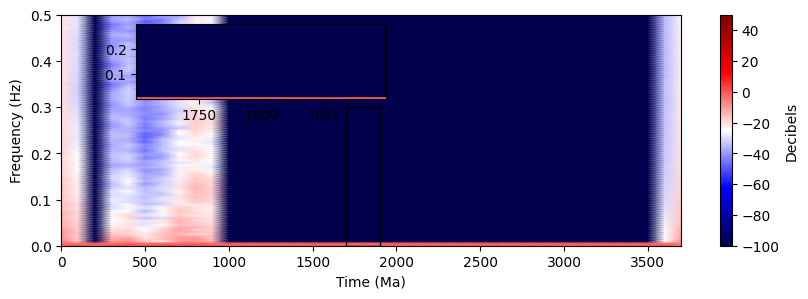

In [32]:
import numpy as np  
import matplotlib.pyplot as plt  
from matplotlib.patches import Rectangle  
  
# db_spectrum 的形状是 (n_times, n_freqs)  
n_times, n_freqs = db_spectrum.shape  
  
# 定义您想要放大的区域  
x_start, x_end = 1700, 1900  # 时间区间的开始和结束  
y_start, y_end = 0.0, 0.3  # 频率区间的开始和结束  

# 定义放大区域的频率范围和时间间隔
zoom_freq_range = (0, 0.3)  # Hz
zoom_time_interval = (selected_start, selected_end)  # Ma

# 索引频率和时间数组以获取放大区域
zoom_freq_indices = np.logical_and(freqs >= zoom_freq_range[0], freqs <= zoom_freq_range[1])
zoom_time_indices = np.logical_and(times >= zoom_time_interval[0], times <= zoom_time_interval[1])

# 提取放大区域的STFT结果
zoom_freqs = freqs[zoom_freq_indices]
zoom_times = times[zoom_time_indices]  # 用times而不是selected_times
zoom_db_spectrum = db_spectrum[zoom_freq_indices, :][:, zoom_time_indices]

# 绘制原始频谱图  
fig, ax1 = plt.subplots(figsize=(10, 3))  
cmap = plt.get_cmap('seismic')  
# 设置 vmin 和 vmax，这里假设您已经有了合适的值  
vmin, vmax = -100, 50  
pcm = ax1.pcolormesh(times, freqs, db_spectrum, cmap=cmap, shading='gouraud', vmin=vmin, vmax=vmax)  
ax1.set_ylabel('Frequency (Hz)')  
ax1.set_xlabel('Time (Ma)')  
# 在原始频谱图上绘制一个矩形，指示将要放大的区域  
rect = Rectangle((x_start, y_start), x_end - x_start, y_end - y_start, edgecolor='black', facecolor='none', linewidth=1)  
ax1.add_patch(rect)  

# 添加颜色条
fig.colorbar(pcm, ax=ax1, label='Decibels')

# 创建局部放大图的子图  
ax2 = fig.add_axes([0.2, 0.6, 0.25, 0.25])  
# 绘制局部放大图的频谱  
ax2.pcolormesh(zoom_times, zoom_freqs, zoom_db_spectrum, cmap=cmap, shading='gouraud', vmin=vmin, vmax=vmax) 
  
# 设置子图的坐标轴  
ax2.set_xticks([1750, 1800, 1850])  
ax2.set_yticks([0.1,0.2])  
 
plt.show()

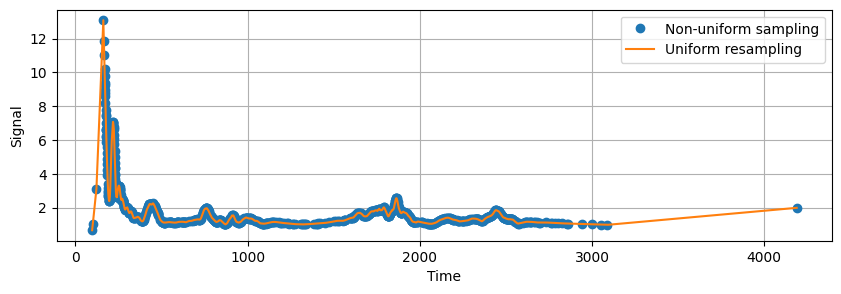

C:\Users\Administrator\AppData\Local\Temp\ipykernel_168568\1423402706.py:24: RuntimeWarning: divide by zero encountered in divide
  period_per_Ma = 1 / (fft_freq * 1e6 * 365.25 * 24 * 60 * 60)


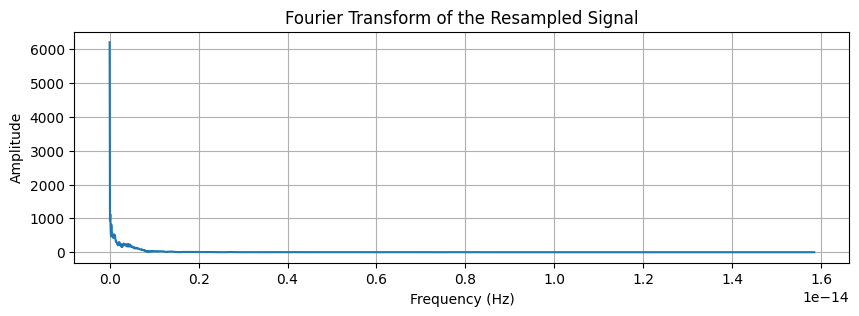

In [33]:
import numpy as np   
import matplotlib.pyplot as plt  

dt_uniform = 1
t_nonuniform = np.array(Middle_Jurassic_smooth_age)
y_nonuniform = np.array(Middle_Jurassic_smooth_freq)
t_uniform, y_uniform = uniform_sampling(t_nonuniform, y_nonuniform, dt_uniform)
  
# 绘制原始非均匀采样和重采样后的均匀采样数据  
plt.figure(figsize=(10, 3))  
plt.plot(t_nonuniform, y_nonuniform, 'o', label='Non-uniform sampling')  
plt.plot(t_uniform, y_uniform, '-', label='Uniform resampling')  
plt.xlabel('Time')  
plt.ylabel('Signal')  
plt.legend()  
plt.grid(True)  
plt.show()  
  
# fft
t_s = dt_uniform * 1e6 * 365.25 * 24 * 60 * 60    
fft_signal = np.fft.rfft(y_uniform)  
fft_freq = np.fft.rfftfreq(len(y_uniform), d=t_s)  

period_per_Ma = 1 / (fft_freq * 1e6 * 365.25 * 24 * 60 * 60)

# 绘制频谱图（如果需要的话）  
plt.figure(figsize=(10, 3))  
plt.plot(fft_freq, np.abs(fft_signal))  
plt.xlabel('Frequency (Hz)')  
plt.ylabel('Amplitude')  
plt.title('Fourier Transform of the Resampled Signal')  
plt.grid(True)  
plt.show()

In [34]:
import numpy as np  
  
# selected_start 和 selected_end 是所选区间的起始和结束索引  
selected_start, selected_end = 1700, 1900  # 您需要设定这些值  
  
# 提取所选区间的信号值  
selected_signal = y_uniform[selected_start:selected_end]  
  
# 计算所选区间的总能量或总幅度（这里以幅度为例）  
total_amplitude_selected = np.sum(np.abs(selected_signal))  
  
# 计算整个信号的总能量或总幅度  
total_amplitude_total = np.sum(np.abs(y_uniform))  
  
# 计算贡献度百分比  
contribution_percentage = (total_amplitude_selected / total_amplitude_total) * 100  
  
print(f"贡献度百分比为：{contribution_percentage:.2f}%")

贡献度百分比为：5.31%


In [35]:
import numpy as np  
from astropy.timeseries import LombScargle 
  
dt_uniform = 1
t_nonuniform = np.array(Middle_Jurassic_smooth_age)
y_nonuniform = np.array(Middle_Jurassic_smooth_freq)
t_uniform, y_uniform = uniform_sampling(t_nonuniform, y_nonuniform, dt_uniform)

# 计算Lomb-Scargle Periodogram  
frequency, power = LombScargle(t_uniform, y_uniform).autopower(maximum_frequency=np.max(np.diff(t_uniform)**(-1)))  
  
# 您感兴趣的时间区间  
selected_start, selected_end = 1700, 1900  
  
# 根据时间区间和采样率估计可能的频率范围  
# 假设采样间隔是均匀的，即 t[1] - t[0]  
sampling_interval = t_uniform[1] - t_uniform[0]  
time_interval = t_uniform[selected_end] - t_uniform[selected_start]  
min_period = time_interval  # 最短周期是时间区间的长度  
max_period = 2 * time_interval  # 最长周期取两倍的时间区间长度作为近似  
min_frequency = 1 / max_period  # 对应的最高频率  
max_frequency = 1 / min_period  # 对应的最低频率  
  
# 在Lomb-Scargle Periodogram中找到对应的功率值  
power_in_range = power[(frequency >= min_frequency) & (frequency <= max_frequency)]  
  
# 计算范围内功率的总和  
total_power_in_range = np.sum(power_in_range)  
  
# 计算Lomb-Scargle Periodogram的总功率  
total_power = np.sum(power)  
  
# 计算贡献率  
if total_power == 0:  
    contribution_rate = 0  
else:  
    contribution_rate = (total_power_in_range / total_power) * 100  
  
print(f"特定时间区间内可能的频率范围: [{min_frequency:.2f}, {max_frequency:.2f}] Hz")  
print(f"该频率范围内的总功率: {total_power_in_range}")  
print(f"Lomb-Scargle Periodogram的总功率: {total_power}")  
print(f"贡献率: {contribution_rate:.2f}%")

特定时间区间内可能的频率范围: [0.00, 0.01] Hz
该频率范围内的总功率: 1.1063138662937755
Lomb-Scargle Periodogram的总功率: 10.107889836333504
贡献率: 10.95%


特定时间区间内的总功率: (1.4718118595398795-0.14119762799930144j)
整个信号的总功率: (31.01434813594733-9.353628982466944e-15j)
贡献率: 4.75-0.46j%


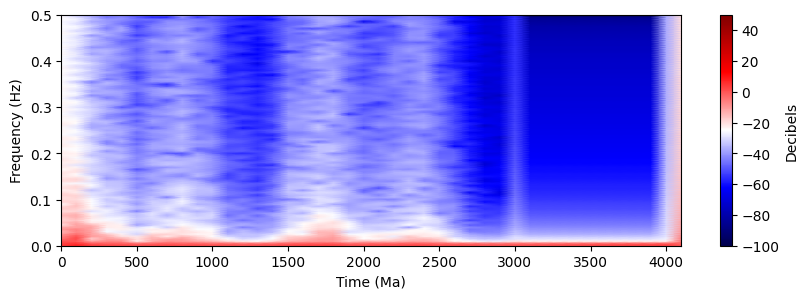

In [36]:
import numpy as np  
from scipy import signal  
import matplotlib.pyplot as plt  
  
dt_uniform = 1
t_nonuniform = np.array(Middle_Jurassic_smooth_age)
y_nonuniform = np.array(Middle_Jurassic_smooth_freq)
t_uniform, y_uniform = uniform_sampling(t_nonuniform, y_nonuniform, dt_uniform)
  
# 您感兴趣的时间区间  
selected_start, selected_end = 1700, 1900  # 注意这里的索引值应根据您的信号数据调整  
  
# 计算STFT  
fs = 1 / (t_uniform[1] - t_uniform[0])  # 采样频率  
nperseg = int(round(fs * 200.00))  # 每个段的长度
noverlap = int(nperseg // 2)  # 重叠的样本数  
freqs, times, Sxx = signal.stft(y_uniform, fs=fs, nperseg=nperseg, noverlap=noverlap, nfft=None, detrend=False, return_onesided=True, boundary='zeros', padded=True)  
  
# 提取所选时间区间的STFT结果  
selected_times = times[(times >= t_uniform[selected_start]) & (times <= t_uniform[selected_end])]  
selected_Sxx = Sxx[:, (times >= t_uniform[selected_start]) & (times <= t_uniform[selected_end])]  
  
# 计算所选时间区间内所有频率的总功率  
total_power_in_selected_time = np.sum(selected_Sxx, axis=1)  
  
# 计算整个信号的总功率  
total_power = np.sum(Sxx)  
  
# 计算贡献率  
if total_power == 0:  
    contribution_rate = 0  
else:  
    contribution_rate = (np.sum(total_power_in_selected_time) / total_power) * 100  
  
print(f"特定时间区间内的总功率: {np.sum(total_power_in_selected_time)}")  
print(f"整个信号的总功率: {total_power}")  
print(f"贡献率: {contribution_rate:.2f}%")  
  
# 绘制幅度谱（取对数前确保没有零值或非常小的值）  
amplitude_spectrum = np.abs(Sxx)  
db_spectrum = 10 * np.log10(amplitude_spectrum + 1e-10)  
  
# 设置图像的最小值和最大值  
vmin, vmax = -100, 50  # 根据你的数据调整这些值  
  
# 绘制 pcolormesh 并设置 vmin 和 vmax
plt.figure(figsize=(10, 3))
cmap = plt.get_cmap('seismic')  # 选择一个预定义的颜色映射       
plt.pcolormesh(times, freqs, db_spectrum, cmap=cmap, shading='gouraud', vmin=vmin, vmax=vmax)  
# 添加颜色条  
cbar = plt.colorbar(label='Decibels')  
# 显示图像  
plt.ylabel('Frequency (Hz)')  
plt.xlabel('Time (Ma)')  
plt.show()

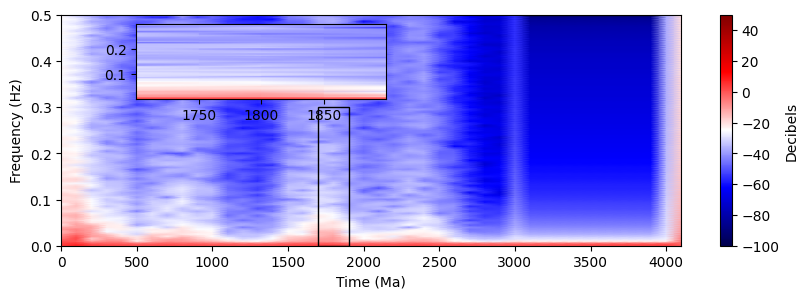

In [37]:
import numpy as np  
import matplotlib.pyplot as plt  
from matplotlib.patches import Rectangle  
  
# db_spectrum 的形状是 (n_times, n_freqs)  
n_times, n_freqs = db_spectrum.shape  
  
# 定义您想要放大的区域  
x_start, x_end = 1700, 1900  # 时间区间的开始和结束  
y_start, y_end = 0.0, 0.3  # 频率区间的开始和结束  

# 定义放大区域的频率范围和时间间隔
zoom_freq_range = (0, 0.3)  # Hz
zoom_time_interval = (selected_start, selected_end)  # Ma

# 索引频率和时间数组以获取放大区域
zoom_freq_indices = np.logical_and(freqs >= zoom_freq_range[0], freqs <= zoom_freq_range[1])
zoom_time_indices = np.logical_and(times >= zoom_time_interval[0], times <= zoom_time_interval[1])

# 提取放大区域的STFT结果
zoom_freqs = freqs[zoom_freq_indices]
zoom_times = times[zoom_time_indices]  # 用times而不是selected_times
zoom_db_spectrum = db_spectrum[zoom_freq_indices, :][:, zoom_time_indices]

# 绘制原始频谱图  
fig, ax1 = plt.subplots(figsize=(10, 3))  
cmap = plt.get_cmap('seismic')  
# 设置 vmin 和 vmax，这里假设您已经有了合适的值  
vmin, vmax = -100, 50  
pcm = ax1.pcolormesh(times, freqs, db_spectrum, cmap=cmap, shading='gouraud', vmin=vmin, vmax=vmax)  
ax1.set_ylabel('Frequency (Hz)')  
ax1.set_xlabel('Time (Ma)')  
# 在原始频谱图上绘制一个矩形，指示将要放大的区域  
rect = Rectangle((x_start, y_start), x_end - x_start, y_end - y_start, edgecolor='black', facecolor='none', linewidth=1)  
ax1.add_patch(rect)  

# 添加颜色条
fig.colorbar(pcm, ax=ax1, label='Decibels')

# 创建局部放大图的子图  
ax2 = fig.add_axes([0.2, 0.6, 0.25, 0.25])  
# 绘制局部放大图的频谱  
ax2.pcolormesh(zoom_times, zoom_freqs, zoom_db_spectrum, cmap=cmap, shading='gouraud', vmin=vmin, vmax=vmax) 
  
# 设置子图的坐标轴  
ax2.set_xticks([1750, 1800, 1850])  
ax2.set_yticks([0.1,0.2])  
 
plt.show()

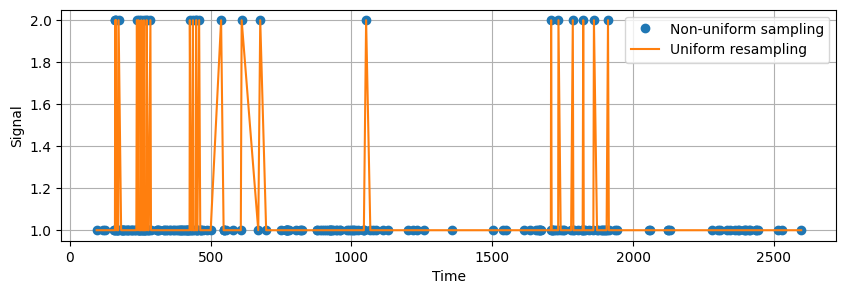

C:\Users\Administrator\AppData\Local\Temp\ipykernel_168568\2664452447.py:24: RuntimeWarning: divide by zero encountered in divide
  period_per_Ma = 1 / (fft_freq * 1e6 * 365.25 * 24 * 60 * 60)


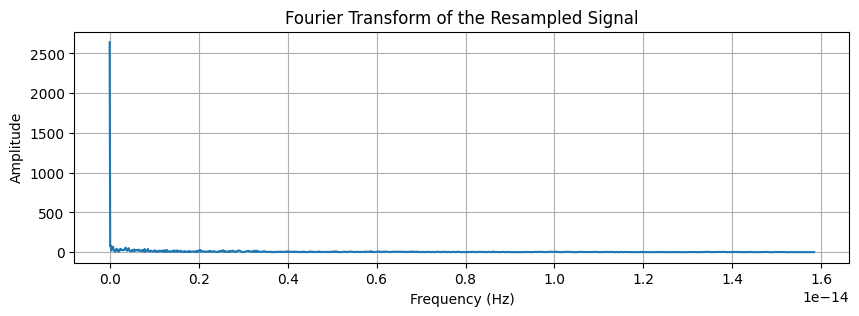

In [38]:
import numpy as np   
import matplotlib.pyplot as plt  

dt_uniform = 1
t_nonuniform = np.array(Upper_Jurassic_smooth_age)
y_nonuniform = np.array(Upper_Jurassic_smooth_freq)
t_uniform, y_uniform = uniform_sampling(t_nonuniform, y_nonuniform, dt_uniform)
  
# 绘制原始非均匀采样和重采样后的均匀采样数据  
plt.figure(figsize=(10, 3))  
plt.plot(t_nonuniform, y_nonuniform, 'o', label='Non-uniform sampling')  
plt.plot(t_uniform, y_uniform, '-', label='Uniform resampling')  
plt.xlabel('Time')  
plt.ylabel('Signal')  
plt.legend()  
plt.grid(True)  
plt.show()  
  
# fft
t_s = dt_uniform * 1e6 * 365.25 * 24 * 60 * 60    
fft_signal = np.fft.rfft(y_uniform)  
fft_freq = np.fft.rfftfreq(len(y_uniform), d=t_s)  

period_per_Ma = 1 / (fft_freq * 1e6 * 365.25 * 24 * 60 * 60)

# 绘制频谱图（如果需要的话）  
plt.figure(figsize=(10, 3))  
plt.plot(fft_freq, np.abs(fft_signal))  
plt.xlabel('Frequency (Hz)')  
plt.ylabel('Amplitude')  
plt.title('Fourier Transform of the Resampled Signal')  
plt.grid(True)  
plt.show()

In [39]:
import numpy as np  
  
# selected_start 和 selected_end 是所选区间的起始和结束索引  
selected_start, selected_end = 1700, 1900  # 您需要设定这些值  
  
# 提取所选区间的信号值  
selected_signal = y_uniform[selected_start:selected_end]  
  
# 计算所选区间的总能量或总幅度（这里以幅度为例）  
total_amplitude_selected = np.sum(np.abs(selected_signal))  
  
# 计算整个信号的总能量或总幅度  
total_amplitude_total = np.sum(np.abs(y_uniform))  
  
# 计算贡献度百分比  
contribution_percentage = (total_amplitude_selected / total_amplitude_total) * 100  
  
print(f"贡献度百分比为：{contribution_percentage:.2f}%")

贡献度百分比为：8.05%


In [41]:
import numpy as np  
from astropy.timeseries import LombScargle 
  
dt_uniform = 1
t_nonuniform = np.array(Upper_Jurassic_smooth_age)
y_nonuniform = np.array(Upper_Jurassic_smooth_freq)
t_uniform, y_uniform = uniform_sampling(t_nonuniform, y_nonuniform, dt_uniform)
  
# 计算Lomb-Scargle Periodogram  
frequency, power = LombScargle(t_uniform, y_uniform).autopower(maximum_frequency=np.max(np.diff(t_uniform)**(-1)))  
  
# 您感兴趣的时间区间  
selected_start, selected_end = 1700, 1900  
  
# 根据时间区间和采样率估计可能的频率范围  
# 假设采样间隔是均匀的，即 t[1] - t[0]  
sampling_interval = t_uniform[1] - t_uniform[0]  
time_interval = t_uniform[selected_end] - t_uniform[selected_start]  
min_period = time_interval  # 最短周期是时间区间的长度  
max_period = 2 * time_interval  # 最长周期取两倍的时间区间长度作为近似  
min_frequency = 1 / max_period  # 对应的最高频率  
max_frequency = 1 / min_period  # 对应的最低频率  
  
# 在Lomb-Scargle Periodogram中找到对应的功率值  
power_in_range = power[(frequency >= min_frequency) & (frequency <= max_frequency)]  
  
# 计算范围内功率的总和  
total_power_in_range = np.sum(power_in_range)  
  
# 计算Lomb-Scargle Periodogram的总功率  
total_power = np.sum(power)  
  
# 计算贡献率  
if total_power == 0:  
    contribution_rate = 0  
else:  
    contribution_rate = (total_power_in_range / total_power) * 100  
  
print(f"特定时间区间内可能的频率范围: [{min_frequency:.2f}, {max_frequency:.2f}] Hz")  
print(f"该频率范围内的总功率: {total_power_in_range}")  
print(f"Lomb-Scargle Periodogram的总功率: {total_power}")  
print(f"贡献率: {contribution_rate:.2f}%")

特定时间区间内可能的频率范围: [0.00, 0.01] Hz
该频率范围内的总功率: 0.2455141436107354
Lomb-Scargle Periodogram的总功率: 10.464063640888519
贡献率: 2.35%


特定时间区间内的总功率: (1.0486943762163712-0.017159841869754715j)
整个信号的总功率: (13.211498499160214-4.107825191113079e-15j)
贡献率: 7.94-0.13j%


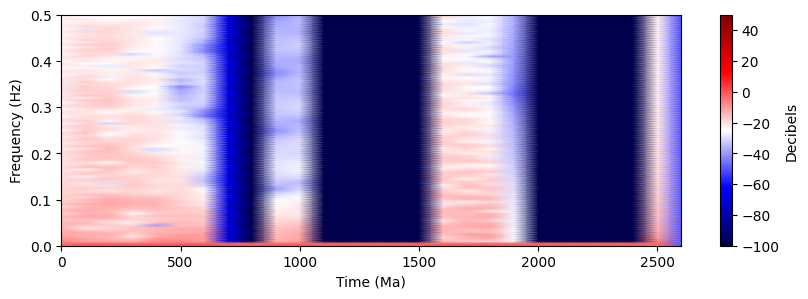

In [42]:
import numpy as np  
from scipy import signal  
import matplotlib.pyplot as plt  
  
dt_uniform = 1
t_nonuniform = np.array(Upper_Jurassic_smooth_age)
y_nonuniform = np.array(Upper_Jurassic_smooth_freq)
t_uniform, y_uniform = uniform_sampling(t_nonuniform, y_nonuniform, dt_uniform)
  
# 您感兴趣的时间区间  
selected_start, selected_end = 1700, 1900  # 注意这里的索引值应根据您的信号数据调整  
  
# 计算STFT  
fs = 1 / (t_uniform[1] - t_uniform[0])  # 采样频率  
nperseg = int(round(fs * 200.00))  # 每个段的长度
noverlap = int(nperseg // 2)  # 重叠的样本数  
freqs, times, Sxx = signal.stft(y_uniform, fs=fs, nperseg=nperseg, noverlap=noverlap, nfft=None, detrend=False, return_onesided=True, boundary='zeros', padded=True)  
  
# 提取所选时间区间的STFT结果  
selected_times = times[(times >= t_uniform[selected_start]) & (times <= t_uniform[selected_end])]  
selected_Sxx = Sxx[:, (times >= t_uniform[selected_start]) & (times <= t_uniform[selected_end])]  
  
# 计算所选时间区间内所有频率的总功率  
total_power_in_selected_time = np.sum(selected_Sxx, axis=1)  
  
# 计算整个信号的总功率  
total_power = np.sum(Sxx)  
  
# 计算贡献率  
if total_power == 0:  
    contribution_rate = 0  
else:  
    contribution_rate = (np.sum(total_power_in_selected_time) / total_power) * 100  
  
print(f"特定时间区间内的总功率: {np.sum(total_power_in_selected_time)}")  
print(f"整个信号的总功率: {total_power}")  
print(f"贡献率: {contribution_rate:.2f}%")  
  
# 绘制幅度谱（取对数前确保没有零值或非常小的值）  
amplitude_spectrum = np.abs(Sxx)  
db_spectrum = 10 * np.log10(amplitude_spectrum + 1e-10)  
  
# 设置图像的最小值和最大值  
vmin, vmax = -100, 50  # 根据你的数据调整这些值  
  
# 绘制 pcolormesh 并设置 vmin 和 vmax
plt.figure(figsize=(10, 3))
cmap = plt.get_cmap('seismic')  # 选择一个预定义的颜色映射       
plt.pcolormesh(times, freqs, db_spectrum, cmap=cmap, shading='gouraud', vmin=vmin, vmax=vmax)  
# 添加颜色条  
cbar = plt.colorbar(label='Decibels')  
# 显示图像  
plt.ylabel('Frequency (Hz)')  
plt.xlabel('Time (Ma)')  
plt.show()

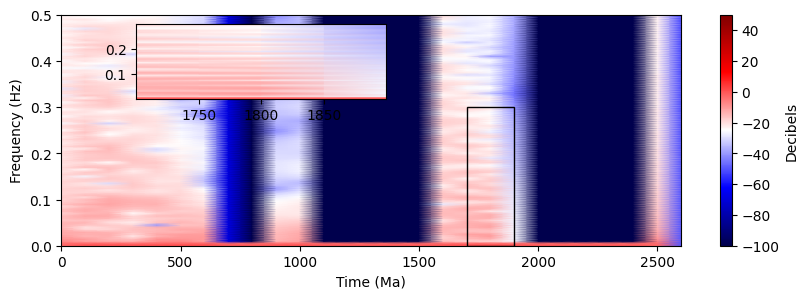

In [43]:
import numpy as np  
import matplotlib.pyplot as plt  
from matplotlib.patches import Rectangle  
  
# db_spectrum 的形状是 (n_times, n_freqs)  
n_times, n_freqs = db_spectrum.shape  
  
# 定义您想要放大的区域  
x_start, x_end = 1700, 1900  # 时间区间的开始和结束  
y_start, y_end = 0.0, 0.3  # 频率区间的开始和结束  

# 定义放大区域的频率范围和时间间隔
zoom_freq_range = (0, 0.3)  # Hz
zoom_time_interval = (selected_start, selected_end)  # Ma

# 索引频率和时间数组以获取放大区域
zoom_freq_indices = np.logical_and(freqs >= zoom_freq_range[0], freqs <= zoom_freq_range[1])
zoom_time_indices = np.logical_and(times >= zoom_time_interval[0], times <= zoom_time_interval[1])

# 提取放大区域的STFT结果
zoom_freqs = freqs[zoom_freq_indices]
zoom_times = times[zoom_time_indices]  # 用times而不是selected_times
zoom_db_spectrum = db_spectrum[zoom_freq_indices, :][:, zoom_time_indices]

# 绘制原始频谱图  
fig, ax1 = plt.subplots(figsize=(10, 3))  
cmap = plt.get_cmap('seismic')  
# 设置 vmin 和 vmax，这里假设您已经有了合适的值  
vmin, vmax = -100, 50  
pcm = ax1.pcolormesh(times, freqs, db_spectrum, cmap=cmap, shading='gouraud', vmin=vmin, vmax=vmax)  
ax1.set_ylabel('Frequency (Hz)')  
ax1.set_xlabel('Time (Ma)')  
# 在原始频谱图上绘制一个矩形，指示将要放大的区域  
rect = Rectangle((x_start, y_start), x_end - x_start, y_end - y_start, edgecolor='black', facecolor='none', linewidth=1)  
ax1.add_patch(rect)  

# 添加颜色条
fig.colorbar(pcm, ax=ax1, label='Decibels')

# 创建局部放大图的子图  
ax2 = fig.add_axes([0.2, 0.6, 0.25, 0.25])  
# 绘制局部放大图的频谱  
ax2.pcolormesh(zoom_times, zoom_freqs, zoom_db_spectrum, cmap=cmap, shading='gouraud', vmin=vmin, vmax=vmax) 
  
# 设置子图的坐标轴  
ax2.set_xticks([1750, 1800, 1850])  
ax2.set_yticks([0.1,0.2])  
 
plt.show()

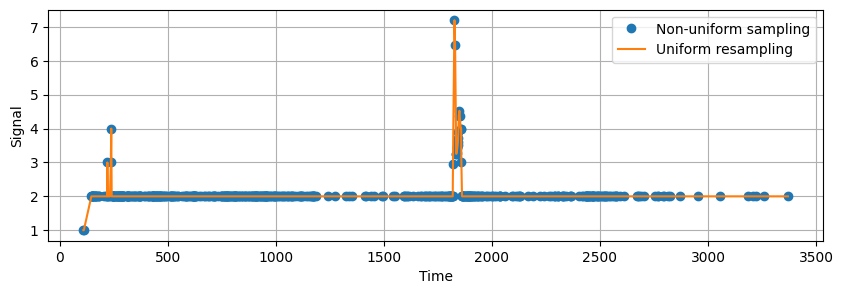

C:\Users\Administrator\AppData\Local\Temp\ipykernel_168568\1204108671.py:24: RuntimeWarning: divide by zero encountered in divide
  period_per_Ma = 1 / (fft_freq * 1e6 * 365.25 * 24 * 60 * 60)


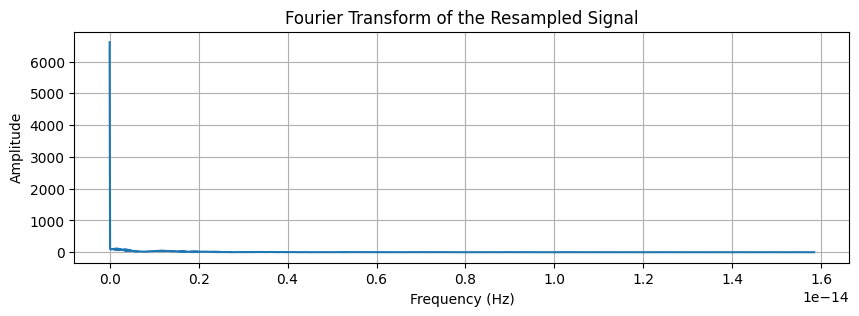

In [44]:
import numpy as np   
import matplotlib.pyplot as plt  

dt_uniform = 1
t_nonuniform = np.array(Lower_Cretaceous_smooth_age)
y_nonuniform = np.array(Lower_Cretaceous_smooth_freq)
t_uniform, y_uniform = uniform_sampling(t_nonuniform, y_nonuniform, dt_uniform)
  
# 绘制原始非均匀采样和重采样后的均匀采样数据  
plt.figure(figsize=(10, 3))  
plt.plot(t_nonuniform, y_nonuniform, 'o', label='Non-uniform sampling')  
plt.plot(t_uniform, y_uniform, '-', label='Uniform resampling')  
plt.xlabel('Time')  
plt.ylabel('Signal')  
plt.legend()  
plt.grid(True)  
plt.show()  
  
# fft
t_s = dt_uniform * 1e6 * 365.25 * 24 * 60 * 60    
fft_signal = np.fft.rfft(y_uniform)  
fft_freq = np.fft.rfftfreq(len(y_uniform), d=t_s)  

period_per_Ma = 1 / (fft_freq * 1e6 * 365.25 * 24 * 60 * 60)

# 绘制频谱图（如果需要的话）  
plt.figure(figsize=(10, 3))  
plt.plot(fft_freq, np.abs(fft_signal))  
plt.xlabel('Frequency (Hz)')  
plt.ylabel('Amplitude')  
plt.title('Fourier Transform of the Resampled Signal')  
plt.grid(True)  
plt.show()

In [45]:
import numpy as np  
  
# selected_start 和 selected_end 是所选区间的起始和结束索引  
selected_start, selected_end = 1700, 1900  # 您需要设定这些值  
  
# 提取所选区间的信号值  
selected_signal = y_uniform[selected_start:selected_end]  
  
# 计算所选区间的总能量或总幅度（这里以幅度为例）  
total_amplitude_selected = np.sum(np.abs(selected_signal))  
  
# 计算整个信号的总能量或总幅度  
total_amplitude_total = np.sum(np.abs(y_uniform))  
  
# 计算贡献度百分比  
contribution_percentage = (total_amplitude_selected / total_amplitude_total) * 100  
  
print(f"贡献度百分比为：{contribution_percentage:.2f}%")

贡献度百分比为：7.53%


In [46]:
import numpy as np  
from astropy.timeseries import LombScargle 
  
dt_uniform = 1
t_nonuniform = np.array(Lower_Cretaceous_smooth_age)
y_nonuniform = np.array(Lower_Cretaceous_smooth_freq)
t_uniform, y_uniform = uniform_sampling(t_nonuniform, y_nonuniform, dt_uniform)
  
# 计算Lomb-Scargle Periodogram  
frequency, power = LombScargle(t_uniform, y_uniform).autopower(maximum_frequency=np.max(np.diff(t_uniform)**(-1)))  
  
# 您感兴趣的时间区间  
selected_start, selected_end = 1700, 1900  
  
# 根据时间区间和采样率估计可能的频率范围  
# 假设采样间隔是均匀的，即 t[1] - t[0]  
sampling_interval = t_uniform[1] - t_uniform[0]  
time_interval = t_uniform[selected_end] - t_uniform[selected_start]  
min_period = time_interval  # 最短周期是时间区间的长度  
max_period = 2 * time_interval  # 最长周期取两倍的时间区间长度作为近似  
min_frequency = 1 / max_period  # 对应的最高频率  
max_frequency = 1 / min_period  # 对应的最低频率  
  
# 在Lomb-Scargle Periodogram中找到对应的功率值  
power_in_range = power[(frequency >= min_frequency) & (frequency <= max_frequency)]  
  
# 计算范围内功率的总和  
total_power_in_range = np.sum(power_in_range)  
  
# 计算Lomb-Scargle Periodogram的总功率  
total_power = np.sum(power)  
  
# 计算贡献率  
if total_power == 0:  
    contribution_rate = 0  
else:  
    contribution_rate = (total_power_in_range / total_power) * 100  
  
print(f"特定时间区间内可能的频率范围: [{min_frequency:.2f}, {max_frequency:.2f}] Hz")  
print(f"该频率范围内的总功率: {total_power_in_range}")  
print(f"Lomb-Scargle Periodogram的总功率: {total_power}")  
print(f"贡献率: {contribution_rate:.2f}%")

特定时间区间内可能的频率范围: [0.00, 0.01] Hz
该频率范围内的总功率: 0.7981446265938028
Lomb-Scargle Periodogram的总功率: 10.230159992884374
贡献率: 7.80%


特定时间区间内的总功率: (1.9999999999999984-7.225096688156714e-16j)
整个信号的总功率: (33.04761204355849-1.3156142841808105e-14j)
贡献率: 6.05+0.00j%


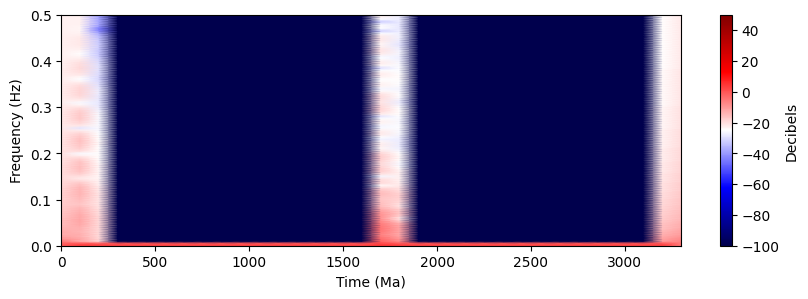

In [47]:
import numpy as np  
from scipy import signal  
import matplotlib.pyplot as plt  
  
dt_uniform = 1
t_nonuniform = np.array(Lower_Cretaceous_smooth_age)
y_nonuniform = np.array(Lower_Cretaceous_smooth_freq)
t_uniform, y_uniform = uniform_sampling(t_nonuniform, y_nonuniform, dt_uniform)
  
# 您感兴趣的时间区间  
selected_start, selected_end = 1700, 1900  # 注意这里的索引值应根据您的信号数据调整  
  
# 计算STFT  
fs = 1 / (t_uniform[1] - t_uniform[0])  # 采样频率  
nperseg = int(round(fs * 200.00))  # 每个段的长度
noverlap = int(nperseg // 2)  # 重叠的样本数  
freqs, times, Sxx = signal.stft(y_uniform, fs=fs, nperseg=nperseg, noverlap=noverlap, nfft=None, detrend=False, return_onesided=True, boundary='zeros', padded=True)  
  
# 提取所选时间区间的STFT结果  
selected_times = times[(times >= t_uniform[selected_start]) & (times <= t_uniform[selected_end])]  
selected_Sxx = Sxx[:, (times >= t_uniform[selected_start]) & (times <= t_uniform[selected_end])]  
  
# 计算所选时间区间内所有频率的总功率  
total_power_in_selected_time = np.sum(selected_Sxx, axis=1)  
  
# 计算整个信号的总功率  
total_power = np.sum(Sxx)  
  
# 计算贡献率  
if total_power == 0:  
    contribution_rate = 0  
else:  
    contribution_rate = (np.sum(total_power_in_selected_time) / total_power) * 100  
  
print(f"特定时间区间内的总功率: {np.sum(total_power_in_selected_time)}")  
print(f"整个信号的总功率: {total_power}")  
print(f"贡献率: {contribution_rate:.2f}%")  
  
# 绘制幅度谱（取对数前确保没有零值或非常小的值）  
amplitude_spectrum = np.abs(Sxx)  
db_spectrum = 10 * np.log10(amplitude_spectrum + 1e-10)  
  
# 设置图像的最小值和最大值  
vmin, vmax = -100, 50  # 根据你的数据调整这些值  
  
# 绘制 pcolormesh 并设置 vmin 和 vmax
plt.figure(figsize=(10, 3))
cmap = plt.get_cmap('seismic')  # 选择一个预定义的颜色映射       
plt.pcolormesh(times, freqs, db_spectrum, cmap=cmap, shading='gouraud', vmin=vmin, vmax=vmax)  
# 添加颜色条  
cbar = plt.colorbar(label='Decibels')  
# 显示图像  
plt.ylabel('Frequency (Hz)')  
plt.xlabel('Time (Ma)')  
plt.show()

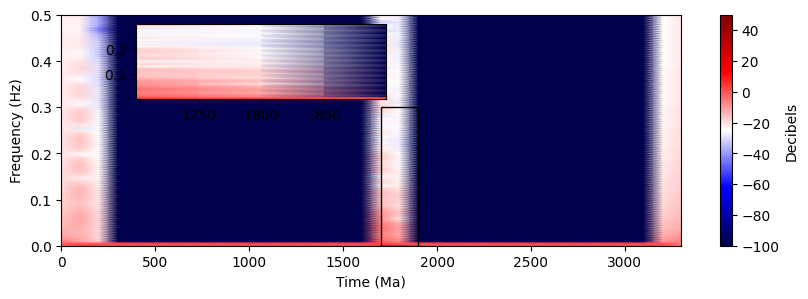

In [48]:
import numpy as np  
import matplotlib.pyplot as plt  
from matplotlib.patches import Rectangle  
  
# db_spectrum 的形状是 (n_times, n_freqs)  
n_times, n_freqs = db_spectrum.shape  
  
# 定义您想要放大的区域  
x_start, x_end = 1700, 1900  # 时间区间的开始和结束  
y_start, y_end = 0.0, 0.3  # 频率区间的开始和结束  

# 定义放大区域的频率范围和时间间隔
zoom_freq_range = (0, 0.3)  # Hz
zoom_time_interval = (selected_start, selected_end)  # Ma

# 索引频率和时间数组以获取放大区域
zoom_freq_indices = np.logical_and(freqs >= zoom_freq_range[0], freqs <= zoom_freq_range[1])
zoom_time_indices = np.logical_and(times >= zoom_time_interval[0], times <= zoom_time_interval[1])

# 提取放大区域的STFT结果
zoom_freqs = freqs[zoom_freq_indices]
zoom_times = times[zoom_time_indices]  # 用times而不是selected_times
zoom_db_spectrum = db_spectrum[zoom_freq_indices, :][:, zoom_time_indices]

# 绘制原始频谱图  
fig, ax1 = plt.subplots(figsize=(10, 3))  
cmap = plt.get_cmap('seismic')  
# 设置 vmin 和 vmax，这里假设您已经有了合适的值  
vmin, vmax = -100, 50  
pcm = ax1.pcolormesh(times, freqs, db_spectrum, cmap=cmap, shading='gouraud', vmin=vmin, vmax=vmax)  
ax1.set_ylabel('Frequency (Hz)')  
ax1.set_xlabel('Time (Ma)')  
# 在原始频谱图上绘制一个矩形，指示将要放大的区域  
rect = Rectangle((x_start, y_start), x_end - x_start, y_end - y_start, edgecolor='black', facecolor='none', linewidth=1)  
ax1.add_patch(rect)  

# 添加颜色条
fig.colorbar(pcm, ax=ax1, label='Decibels')

# 创建局部放大图的子图  
ax2 = fig.add_axes([0.2, 0.6, 0.25, 0.25])  
# 绘制局部放大图的频谱  
ax2.pcolormesh(zoom_times, zoom_freqs, zoom_db_spectrum, cmap=cmap, shading='gouraud', vmin=vmin, vmax=vmax) 
  
# 设置子图的坐标轴  
ax2.set_xticks([1750, 1800, 1850])  
ax2.set_yticks([0.1,0.2])  
 
plt.show()

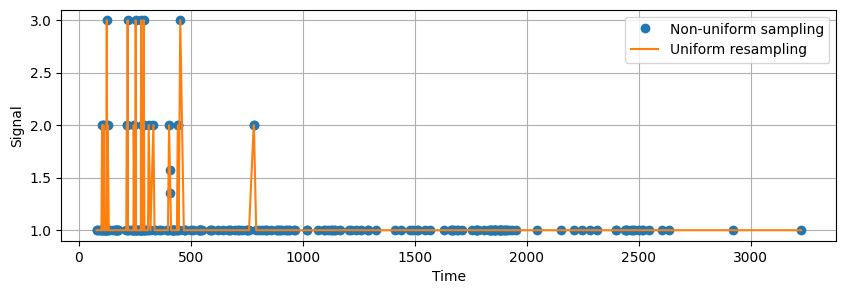

C:\Users\Administrator\AppData\Local\Temp\ipykernel_168568\3451273053.py:24: RuntimeWarning: divide by zero encountered in divide
  period_per_Ma = 1 / (fft_freq * 1e6 * 365.25 * 24 * 60 * 60)


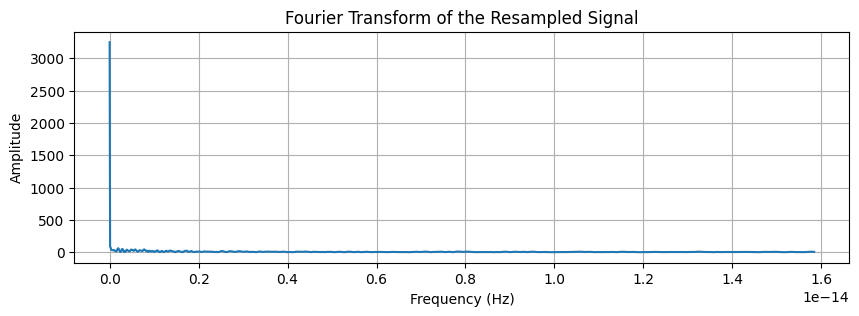

In [49]:
import numpy as np   
import matplotlib.pyplot as plt  

dt_uniform = 1
t_nonuniform = np.array(Upper_Cretaceous_smooth_age)
y_nonuniform = np.array(Upper_Cretaceous_smooth_freq)
t_uniform, y_uniform = uniform_sampling(t_nonuniform, y_nonuniform, dt_uniform)
  
# 绘制原始非均匀采样和重采样后的均匀采样数据  
plt.figure(figsize=(10, 3))  
plt.plot(t_nonuniform, y_nonuniform, 'o', label='Non-uniform sampling')  
plt.plot(t_uniform, y_uniform, '-', label='Uniform resampling')  
plt.xlabel('Time')  
plt.ylabel('Signal')  
plt.legend()  
plt.grid(True)  
plt.show()  
  
# fft
t_s = dt_uniform * 1e6 * 365.25 * 24 * 60 * 60    
fft_signal = np.fft.rfft(y_uniform)  
fft_freq = np.fft.rfftfreq(len(y_uniform), d=t_s)  

period_per_Ma = 1 / (fft_freq * 1e6 * 365.25 * 24 * 60 * 60)

# 绘制频谱图（如果需要的话）  
plt.figure(figsize=(10, 3))  
plt.plot(fft_freq, np.abs(fft_signal))  
plt.xlabel('Frequency (Hz)')  
plt.ylabel('Amplitude')  
plt.title('Fourier Transform of the Resampled Signal')  
plt.grid(True)  
plt.show()

In [50]:
import numpy as np  
  
# selected_start 和 selected_end 是所选区间的起始和结束索引  
selected_start, selected_end = 1700, 1900  # 您需要设定这些值  
  
# 提取所选区间的信号值  
selected_signal = y_uniform[selected_start:selected_end]  
  
# 计算所选区间的总能量或总幅度（这里以幅度为例）  
total_amplitude_selected = np.sum(np.abs(selected_signal))  
  
# 计算整个信号的总能量或总幅度  
total_amplitude_total = np.sum(np.abs(y_uniform))  
  
# 计算贡献度百分比  
contribution_percentage = (total_amplitude_selected / total_amplitude_total) * 100  
  
print(f"贡献度百分比为：{contribution_percentage:.2f}%")

贡献度百分比为：6.16%


In [51]:
import numpy as np  
from astropy.timeseries import LombScargle 
  
dt_uniform = 1
t_nonuniform = np.array(Upper_Cretaceous_smooth_age)
y_nonuniform = np.array(Upper_Cretaceous_smooth_freq)
t_uniform, y_uniform = uniform_sampling(t_nonuniform, y_nonuniform, dt_uniform)
  
# 计算Lomb-Scargle Periodogram  
frequency, power = LombScargle(t_uniform, y_uniform).autopower(maximum_frequency=np.max(np.diff(t_uniform)**(-1)))  
  
# 您感兴趣的时间区间  
selected_start, selected_end = 1700, 1900  
  
# 根据时间区间和采样率估计可能的频率范围  
# 假设采样间隔是均匀的，即 t[1] - t[0]  
sampling_interval = t_uniform[1] - t_uniform[0]  
time_interval = t_uniform[selected_end] - t_uniform[selected_start]  
min_period = time_interval  # 最短周期是时间区间的长度  
max_period = 2 * time_interval  # 最长周期取两倍的时间区间长度作为近似  
min_frequency = 1 / max_period  # 对应的最高频率  
max_frequency = 1 / min_period  # 对应的最低频率  
  
# 在Lomb-Scargle Periodogram中找到对应的功率值  
power_in_range = power[(frequency >= min_frequency) & (frequency <= max_frequency)]  
  
# 计算范围内功率的总和  
total_power_in_range = np.sum(power_in_range)  
  
# 计算Lomb-Scargle Periodogram的总功率  
total_power = np.sum(power)  
  
# 计算贡献率  
if total_power == 0:  
    contribution_rate = 0  
else:  
    contribution_rate = (total_power_in_range / total_power) * 100  
  
print(f"特定时间区间内可能的频率范围: [{min_frequency:.2f}, {max_frequency:.2f}] Hz")  
print(f"该频率范围内的总功率: {total_power_in_range}")  
print(f"Lomb-Scargle Periodogram的总功率: {total_power}")  
print(f"贡献率: {contribution_rate:.2f}%")

特定时间区间内可能的频率范围: [0.00, 0.01] Hz
该频率范围内的总功率: 0.16124801988801102
Lomb-Scargle Periodogram的总功率: 10.461560829235928
贡献率: 1.54%


特定时间区间内的总功率: (0.9999999999999941+3.7107377289782425e-15j)
整个信号的总功率: (16.21138679298434-7.549516567451064e-15j)
贡献率: 6.17+0.00j%


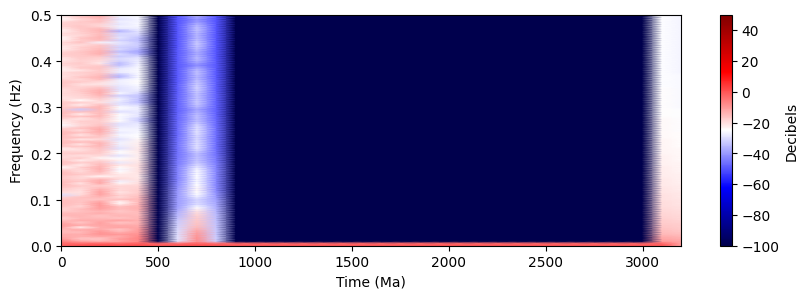

In [52]:
import numpy as np  
from scipy import signal  
import matplotlib.pyplot as plt  
  
dt_uniform = 1
t_nonuniform = np.array(Upper_Cretaceous_smooth_age)
y_nonuniform = np.array(Upper_Cretaceous_smooth_freq)
t_uniform, y_uniform = uniform_sampling(t_nonuniform, y_nonuniform, dt_uniform)
  
# 您感兴趣的时间区间  
selected_start, selected_end = 1700, 1900  # 注意这里的索引值应根据您的信号数据调整  
  
# 计算STFT  
fs = 1 / (t_uniform[1] - t_uniform[0])  # 采样频率  
nperseg = int(round(fs * 200.00))  # 每个段的长度
noverlap = int(nperseg // 2)  # 重叠的样本数  
freqs, times, Sxx = signal.stft(y_uniform, fs=fs, nperseg=nperseg, noverlap=noverlap, nfft=None, detrend=False, return_onesided=True, boundary='zeros', padded=True)  
  
# 提取所选时间区间的STFT结果  
selected_times = times[(times >= t_uniform[selected_start]) & (times <= t_uniform[selected_end])]  
selected_Sxx = Sxx[:, (times >= t_uniform[selected_start]) & (times <= t_uniform[selected_end])]  
  
# 计算所选时间区间内所有频率的总功率  
total_power_in_selected_time = np.sum(selected_Sxx, axis=1)  
  
# 计算整个信号的总功率  
total_power = np.sum(Sxx)  
  
# 计算贡献率  
if total_power == 0:  
    contribution_rate = 0  
else:  
    contribution_rate = (np.sum(total_power_in_selected_time) / total_power) * 100  
  
print(f"特定时间区间内的总功率: {np.sum(total_power_in_selected_time)}")  
print(f"整个信号的总功率: {total_power}")  
print(f"贡献率: {contribution_rate:.2f}%")  
  
# 绘制幅度谱（取对数前确保没有零值或非常小的值）  
amplitude_spectrum = np.abs(Sxx)  
db_spectrum = 10 * np.log10(amplitude_spectrum + 1e-10)  
  
# 设置图像的最小值和最大值  
vmin, vmax = -100, 50  # 根据你的数据调整这些值  
  
# 绘制 pcolormesh 并设置 vmin 和 vmax
plt.figure(figsize=(10, 3))
cmap = plt.get_cmap('seismic')  # 选择一个预定义的颜色映射       
plt.pcolormesh(times, freqs, db_spectrum, cmap=cmap, shading='gouraud', vmin=vmin, vmax=vmax)  
# 添加颜色条  
cbar = plt.colorbar(label='Decibels')  
# 显示图像  
plt.ylabel('Frequency (Hz)')  
plt.xlabel('Time (Ma)')  
plt.show()

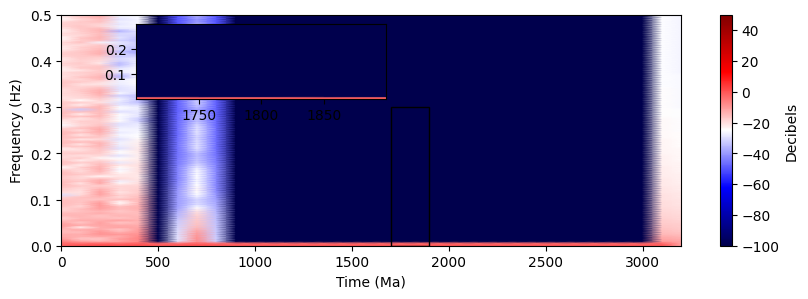

In [53]:
import numpy as np  
import matplotlib.pyplot as plt  
from matplotlib.patches import Rectangle  
  
# db_spectrum 的形状是 (n_times, n_freqs)  
n_times, n_freqs = db_spectrum.shape  
  
# 定义您想要放大的区域  
x_start, x_end = 1700, 1900  # 时间区间的开始和结束  
y_start, y_end = 0.0, 0.3  # 频率区间的开始和结束  

# 定义放大区域的频率范围和时间间隔
zoom_freq_range = (0, 0.3)  # Hz
zoom_time_interval = (selected_start, selected_end)  # Ma

# 索引频率和时间数组以获取放大区域
zoom_freq_indices = np.logical_and(freqs >= zoom_freq_range[0], freqs <= zoom_freq_range[1])
zoom_time_indices = np.logical_and(times >= zoom_time_interval[0], times <= zoom_time_interval[1])

# 提取放大区域的STFT结果
zoom_freqs = freqs[zoom_freq_indices]
zoom_times = times[zoom_time_indices]  # 用times而不是selected_times
zoom_db_spectrum = db_spectrum[zoom_freq_indices, :][:, zoom_time_indices]

# 绘制原始频谱图  
fig, ax1 = plt.subplots(figsize=(10, 3))  
cmap = plt.get_cmap('seismic')  
# 设置 vmin 和 vmax，这里假设您已经有了合适的值  
vmin, vmax = -100, 50  
pcm = ax1.pcolormesh(times, freqs, db_spectrum, cmap=cmap, shading='gouraud', vmin=vmin, vmax=vmax)  
ax1.set_ylabel('Frequency (Hz)')  
ax1.set_xlabel('Time (Ma)')  
# 在原始频谱图上绘制一个矩形，指示将要放大的区域  
rect = Rectangle((x_start, y_start), x_end - x_start, y_end - y_start, edgecolor='black', facecolor='none', linewidth=1)  
ax1.add_patch(rect)  

# 添加颜色条
fig.colorbar(pcm, ax=ax1, label='Decibels')

# 创建局部放大图的子图  
ax2 = fig.add_axes([0.2, 0.6, 0.25, 0.25])  
# 绘制局部放大图的频谱  
ax2.pcolormesh(zoom_times, zoom_freqs, zoom_db_spectrum, cmap=cmap, shading='gouraud', vmin=vmin, vmax=vmax) 
  
# 设置子图的坐标轴  
ax2.set_xticks([1750, 1800, 1850])  
ax2.set_yticks([0.1,0.2])  
 
plt.show()

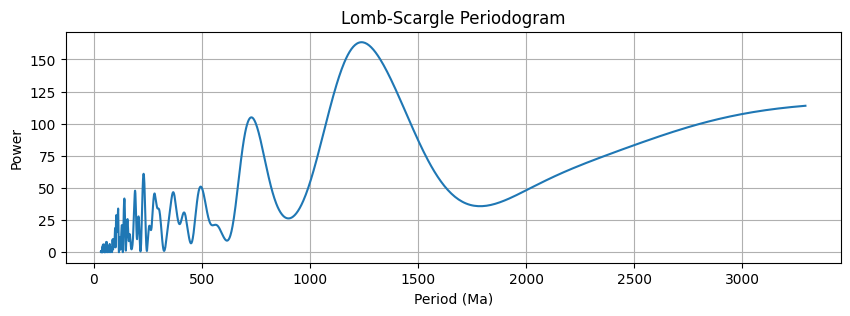

Best period found: 1240.26 Ma


In [ ]:
from astropy.timeseries import LombScargle 
import numpy as np  
import matplotlib.pyplot as plt  
  
# 假设你有一个时间序列t（以Ma为单位）和对应的信号值y  
t = t_uniform  
y = y_uniform     

# 创建Lomb-Scargle对象并拟合数据  
frequency = np.linspace(1. / (t.max() - t.min()), 100. / (t.max() - t.min()), 10000)  # 频率范围  
ls = LombScargle(t, y, normalization='psd')  
power = ls.power(frequency)  
  
# 绘制周期图
plt.figure(figsize=(10, 3))   
plt.plot(1. / frequency, power)  
plt.xlabel('Period (Ma)')  
plt.ylabel('Power')  
plt.title('Lomb-Scargle Periodogram')  
plt.grid(True)  
plt.show()  
  
# 寻找最大功率对应的周期  
best_period = 1. / frequency[np.argmax(power)]  
print(f"Best period found: {best_period:.2f} Ma")